# BRICS Astronomy/Data Analytics Course 2026 - Capstone Project

# **Unsupervised Anomaly Detection in TESS Light Curves Using Isolation Forest and Dense Autoencoder**
<br>

Name: Prasad Senthilvelu

Email: prasadsenthilvelu@gmail.com

## **Table of Contents:**

1. [Before You Begin](#scrollTo=MYRVtZaH3G5w&line=8&uniqifier=1)
2. [Project Overview and Dataset](#scrollTo=sh9PFs9nENlL)
3. [Part 1 - Extraction and Preprocessing of the lightcurves](#scrollTo=zx0nmLJnOZS_)
4. [Part 2 - Feature Extraction](#scrollTo=Glz5xt35P1g7)
5. [Part 3 - Implementation of selected unsupervised machine learning algorithms](#scrollTo=d2b9i1vOUvCf)
6. [Part 4 - Conclusion](#scrollTo=RpxG2U-Utjba)
7. [Part 5 - Future Work](#scrollTo=vclcpzn6ueKx)
8. [References](#scrollTo=N8K_6KZQujIO)



## **Before you begin** :

Before executing the notebook, 2 CSV files are required to run the code:

1. TESS Sector 40 Dataset CSV File - Primary Dataset
2. Extracted Features of Sector 40 stars CSV File

I have chosen to give the intermediate output - the extracted features of sector 40 stars - as a CSV file, rather than making you run the code, since it took me well over 12 hours to execute it fully. However, if you wish to run the code, it is given below, and can be executed if needed. More information on it in [execution of feature extraction](#scrollTo=Ol5qXRjKQH38&line=9&uniqifier=1).


To ensure this works on **Google Colab**, please execute the cell below to mount your Google Drive:

In [ ]:
import os
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


The cell below has been created to automatically download the 2 CSV files (mentioned above) from my Google Drive and save it in yours.

Here are the steps that are taken to do this:

1. Defining the directory path and creating the folder in your Google Drive (named **`TESS_AnomalyDet_PrasadS`**)

2. Downloading the CSV files from my Google Drive, into the "TESS_AnomalyDet_PrasadS" Folder (created) in your Google Drive.

<br>

**Note:** *By running the code cell below, you consent to creating this folder and downloading these files directly into your Google Drive environment. Thank you!*

In [ ]:
# 1. Defining the directory path and create the folder in Google Drive
project_dir = Path("/content/drive/MyDrive/TESS_AnomalyDet_PrasadS")
project_dir.mkdir(parents=True, exist_ok=True)

# 2. Downloading the CSV files directly into the Google Drive folder
TESSdata_sector40 = '113ts7yz_ITEVO1n3cJfhuO4J56wOuMHg'
sect40_features = '1zpTu3hHYMEx1mNpnVKusJfexBxULdR6N'

TESSdata_sector40_path = project_dir / "TESS_Sector40_Dataset.csv"
sect40_features_path = project_dir / "TESS_Sector40_ExtFeatures.csv"

# Downloading TESS Sector 40 Dataset:
if not TESSdata_sector40_path.exists():
    !gdown {TESSdata_sector40} -O "{TESSdata_sector40_path}"

# Downloading The Extracted Features CSV:
if not sect40_features_path.exists():
    !gdown {sect40_features} -O "{sect40_features_path}"

print("Setup complete! Files are saved in:", project_dir)

Setup complete! Files are saved in: /content/drive/MyDrive/TESS_AnomalyDet_PrasadS


Given that these 2 files are downloaded and saved accordingly, executing this Google Colab notebook will not take longer than **15-20 minutes**.

## **Project Overview and Dataset** :    





Light curves are graphs that show the brightness of an object over a period of time. Modern astronomical surveys such as TESS continuously generate voluminous amounts of time-series data in the form of stellar light curves. While most celestial objects will exhibit expected patterns of variability, a small fraction of them may display unusual behaviour (which can be studied by observing their light curves). These objects are referred to as **anomalies** or outliers. These anomalies can either be due to real astrophysical phenomena or instrumental artefacts (instrumental errors). While the primary focus will be on detecting real astrophysical phenomena, both types of anomalies need to be studied in depth to improve the overall detection.

Since manually inspecting each light curve, out of the thousands, is impractical in nature, we can utilize machine learning to allow us to efficiently and automatically identify these unusual observations.

In this project, unsupervised (unlabelled data) anomaly detection is applied to **TESS light curves**. While NASA’s TESS mission was created to discover exoplanets, the fact that it monitors and detects variations in brightness from all objects it detects, it has allowed us to also detect various stellar objects, from nearby asteroids to pulsating stars and more. TESS has completed its initially planned two-year primary mission and continues its search for new exoplanets.

This project focuses on identifying anomalies through two fundamentally different algorithms, namely **Isolation Forest**and **Dense AutoEncoder**. The top anomalies detected by these algorithms are then compared to see how closely they agree with each other. A higher agreement would suggest a greater robustness of the obtained results / anomalies.

I have used the **TESS Sector 40** target list as the primary dataset for this project. It has already been saved in your Google Drive, if you have executed the cell above.





## **Fundamental Workflow**

Here is a brief workflow of the project. We start by extracting and preprocessing the light curves of objects from sector 40 and storing them in a DataFrame. The preprocessed dataset of light curves is then used to extract about 50 different features, which contain both statistical and time-domain features. Next, the DataFrame of features is used to implement Isolation Forest, followed by SHAP (Shapley Additive exPlanations). The results from Isolation Forest are stored. On the other hand, Isolation Forest is again utilized to find non-anomalous objects to train the Dense autoencoder, before using it to find anomalies. This is followed by reconstruction error plots, which are equivalent in essence to the SHAP plots, and the results from the dense autoencoder are stored.

Here is a flowchart that can help with a quick overview:

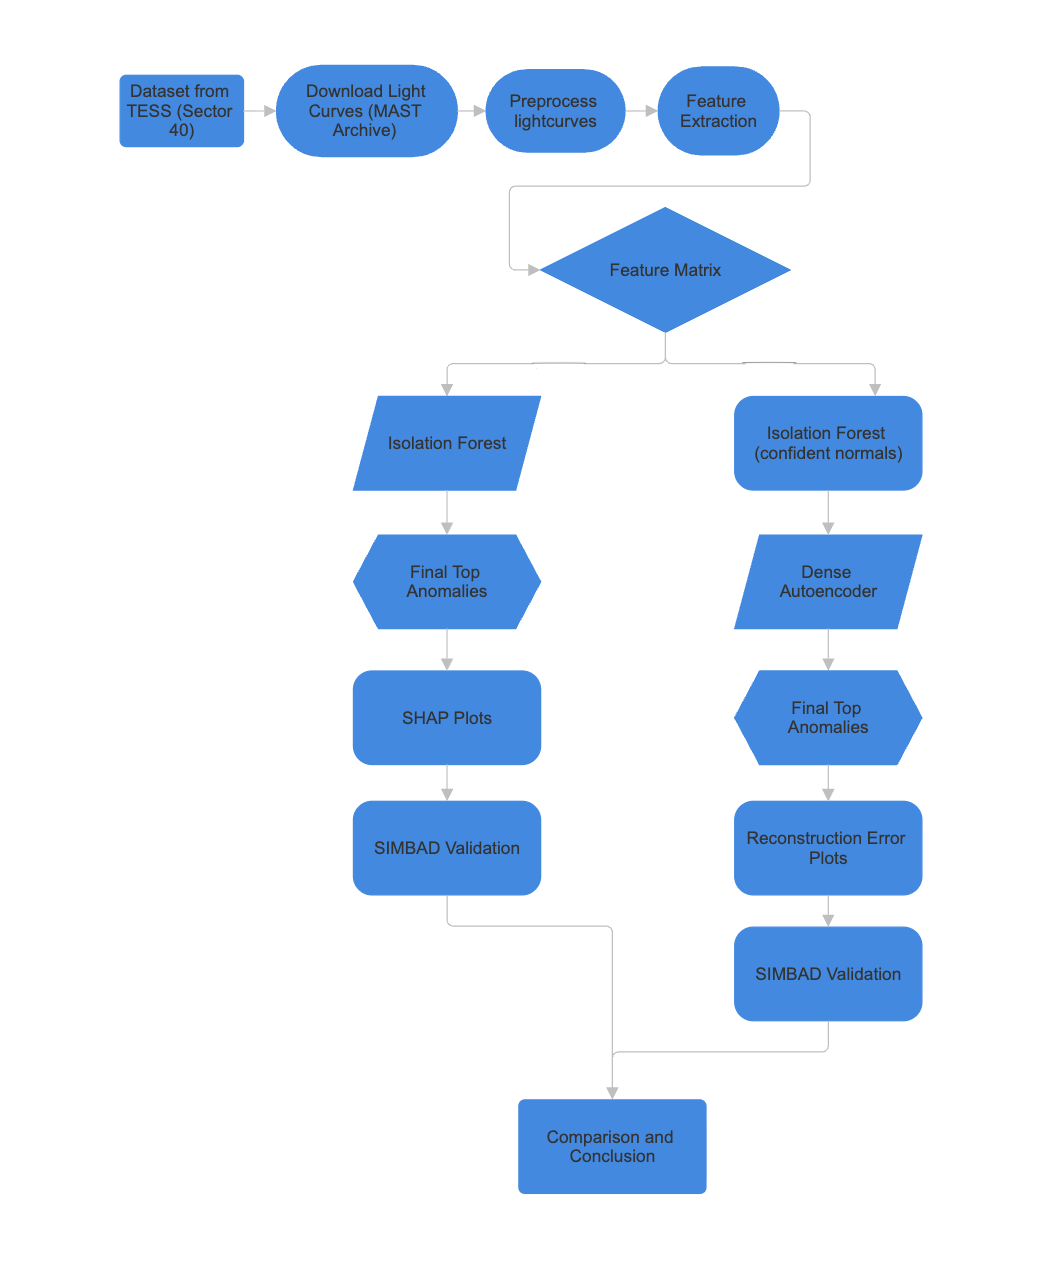




## **Part 1 - Extraction and Preprocessing of the lightcurves**

The following libraries provide the functionality required for this project, including TESS light curve retrieval, scientific computing, feature extraction, machine learning, visualization, and astronomical database queries.

Please uncomment the code in the next cell and execute it if you don't already have these packages in your Google Colab Environment.


In [ ]:
#!pip install lightkurve astroquery astropy numpy scipy pandas tensorflow scikit-learn matplotlib seaborn shap

In [ ]:
# For Data retrieval and astronomy:
import lightkurve as lk
from astroquery.mast import Catalogs
from astroquery.simbad import Simbad
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.stats import sigma_clip
from lightkurve import LightkurveWarning

#For Computing and Data Handling:
import numpy as np
import scipy
import time
import warnings
import pandas as pd

#For Feature Extraction:
from scipy.signal import find_peaks
from scipy.stats import linregress
from scipy.signal import peak_prominences
from scipy.signal import peak_widths

#Machine Learning:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA


# For Visualization and Interpretation:
import matplotlib.pyplot as plt
import seaborn as sns
import shap

%matplotlib inline

The table below will give a quick overview of the imported packages and their relevance:  





| Package | Purpose |
|---------|---------|
| **Lightkurve** | Download and manipulate TESS light curves |
| **NumPy / Pandas / SciPy** | Numerical computing and feature calculations |
| **Astropy** | Astronomical utilities and sigma clipping |
| **Scikit-learn** | Feature scaling, PCA, Isolation Forest |
| **TensorFlow** | Dense Autoencoder implementation |
| **Matplotlib / Seaborn** | Data visualization |
| **SHAP** | Model explainability for Isolation Forest |
| **Astroquery** | Query MAST and SIMBAD databases |

### Light Curve Extraction

The Lightkurve package is used to query the MAST (Mikulski Archive for Space Telescopes) archive, which hosts the publicly available TESS observations. Each object has its own designated TIC ID, which acts as a unique alphanumeric identifier. For each TIC ID in the dataset, the function downloads the corresponding 20-second cadence.

A 20-second cadence simply means that the telescope records and downloads brightness measurements for specific stars every 20 seconds. (exptime=20) This high frequency adds more detail to the light curves.

We choose the ‘author’ as the **SPOC** (Science Processing Operations Center), which translates to saying that we want the light curves that came through their data processing pipeline. This pipeline builds on the legacy of the Kepler data processing pipeline.

The PDCSAP (Pre-search Data Conditioning Simple Aperture Photometry) flux is used instead of the raw SAP flux, because, to a certain extent, instrumental noise has been removed, while preserving genuine astrophysical variability. Thus, this would be more suitable for feature extraction and anomaly detection.

TESS sectors refer to specific and distinct strips of the sky. As mentioned earlier, for this project, I have utilized data of all objects from sector 40. Some TIC ID in the selected sector may fail to download. The except block handles this so that such cases are automatically skipped.


In [ ]:
def extract_lightcurve(ID,sect_no):

    #Converting the numerical TIC ID into the format expected by the light curve:
    tic = str('TIC '+f'{ID}')

    try:
        data = lk.search_lightcurve(tic, mission = 'TESS', author = 'SPOC', exptime=20, sector=sect_no)
        #Skipping if there are no existing observations for this TIC ID:

        if len(data) == 0:
            return None

        #Downloading the PDCSAP flux:
        lc = data.download(flux_column='pdcsap_flux')

    except Exception as e:

        #Skipping any targets whose corresponding lightcurve cannot be retrieved:
        print(f"Skipping TIC {tic}: {e}")

        return None

    return lc

### Light Curve Preprocessing

Raw TESS light curves often contain missing measurements and instrumental artefacts. These can directly influence feature extraction and anomaly detection. Therefore, it would be ideal to remove such signatures from the light curves to our best capacity, while ensuring meaningful data remains unaffected. Since anomaly detection thrives on detecting outliers in terms of features, we cannot be too harsh with preprocessing the data.

Every TESS cadence is assigned a quality flag by the SPOC pipeline that records potential issues. These issues can be cosmic-ray events, spacecraft momentum dumps, etc. These quality flags encode this information by using specific numbers that correspond to different issues. Here, I remove cadences whose quality flags match the set of flags recommended for exclusion in the [official TESS SPOC documentation](https://outerspace.stsci.edu/spaces/TESS/pages/14563420/2.0+-+Data+Product+Overview).

If less than 80% of cadences remain after the filtering process using quality flags, the entire light curve is discarded, as the remaining data may not provide a complete idea or representation of that object’s variability.

Sigma clipping is applied to remove extreme outliers / isolated spikes in the flux measurements. A threshold of **5σ** is used to eliminate such isolated spikes that are more likely to arise from instrumental artefacts than genuine astrophysical events.

Furthermore, light curves with a median flux extremely close to zero are discarded before normalization, as if not handled, normalization would lead to a division by a near-zero value and the production of unreliable feature values.  This function was created on a trial-and-error basis, after observing the errors obtained in the second half of this project.


In [ ]:
# This function can be edited further when required, to include more preprocessing aspects.
def preprocess_lc(lc):

    # Removing missing values:
    lc= lc.remove_nans()

    # Remove cadences affected by instrumental artefacts using the recommended SPOC quality flags for exclusion.
    BAD_MASK = ( 1 | 2 | 4 | 8 | 16 | 32 | 128 | 512 | 4096 | 16384 )
    # Bitmask corresponding to the cadence quality flags recommended for exclusion
    # in the official TESS SPOC documentation. (https://outerspace.stsci.edu/spaces/TESS/pages/14563420/2.0+-+Data+Product+Overview)

    good_mask = (lc.quality & BAD_MASK) == 0

    # Calculating the fracion of points that pass the good_mask filter:
    fraction_good = np.sum(good_mask) / len(good_mask)

    # If a large number of points were removed due to the filter, then it's better to discard the object.
    # I have used a threshold of 20% of bad points:
    if fraction_good < 0.80:
        return None

    lc = lc[good_mask]

    # Using Sigma Clipping to remove isolated flux outliers using 5σ sigma clipping:

    flux_sigma = np.asarray(lc.flux.value)
    masked = sigma_clip(flux_sigma, sigma=5)
    good = ~masked.mask
    lc = lc[good]

    # To skip light curves that cannot be reliably normalized:
    median_flux = np.median(lc.flux.value)
    if abs(median_flux) < 1e-3:
        return None

    # Normalizing the light curve:
    lc_clean = lc.normalize()

    return lc_clean

## **Part 2 - Feature Extraction**

Rather than feeding the raw light curves directly to the machine learning models, each light curve is summarized using a set of descriptive statistical and variability features. These features provide a compact numerical representation of the light curve while preserving its important characteristics. A total of 48 features were calculated for each (preprocessed) light curve.

These features capture different aspects of the time series, including statistical properties, variability, periodicity, trends, and noise characteristics.







In [ ]:
# Defining a function to extract features - CAN BE EDITED TO ADD/EXTRACT MORE FEATURES
def feature_extraction(ID,lc_cleaned):

    features = {}

    features["TIC ID"] = ID
    features["Sector"] = lc_cleaned.meta["SECTOR"]

    flux = np.array(lc_cleaned.flux.value)
    time = np.array(lc_cleaned.time.value)

    avg_flux = np.mean(flux)
    median_flux = np.median(flux)

    stdev_flux = np.std(flux)
    variance_flux = np.var(flux)

    #Statistics:
    features["Mean Flux"] = avg_flux
    features["Median Flux"] = median_flux
    features["Std flux"] = stdev_flux
    features["Variance Flux"] = variance_flux


    max_flux = np.max(flux)
    min_flux = np.min(flux)
    amp_flux = max_flux - min_flux
    rel_amp_flux = (max_flux - min_flux) / avg_flux
    percentile_amp = (np.percentile(flux,95) - np.percentile(flux,5))

    #Amplitudes:
    features["Amplitude"] = amp_flux
    features["Relative Amplitude"] = rel_amp_flux
    features["Percentile Amplitude"] = percentile_amp


    iqr_q1 = np.percentile(flux,25)
    iqr_q3 = np.percentile(flux,75)
    iqr = iqr_q3 - iqr_q1

    #Interquartile Range:
    features["IQR"] = iqr

    #Signal to Noise Ratio (SNR):
        #High SNR ---> Good; Less Noise
        #Low SNR ----> Bad; More Noise
        # The reason why I didn't use this to eliminate stars in the preprocessing function
        #is because it might remove scientifically meaningful anomalies as well
        #rather, keeping it as a feature allows us to check later, whether the flagged anomalies have low or high SNR
    snr = np.median(lc_cleaned.flux.value) / np.median(lc_cleaned.flux_err.value)
    features["SNR"] = float(snr)


    skewness = scipy.stats.skew(flux)
    kurtosis = scipy.stats.kurtosis(flux)

    #Distribution Shape:
    features["skewness"] = skewness
    features["kurtosis"] = kurtosis

    pg = lc_cleaned.to_periodogram(method = 'lombscargle')

    period_max = pg.period_at_max_power.value
    period = pg.period.value
    max_power = pg.max_power.value

    power = pg.power.value
    peaks,properties = find_peaks(power)
    threshold = 0.5*np.max(power)
    sig_peaks = []
    for i in peaks:
        if power[i] > threshold:
            sig_peaks.append(i)
    num_peaks = len(sig_peaks)

    #Periodicity Features:
    features["Dominant Period"] = period_max
    features["Maximum PG Power"] = max_power
    features["No. of Sig. Peaks"] = num_peaks

    all_slopes = np.diff(flux) / np.diff(time)
    max_slope = np.max(np.abs(all_slopes))

    beyond = np.abs(flux - avg_flux) > 2*stdev_flux
    beyond2std = np.sum(beyond) / len(flux)

    #Further Statistics:
    features["Maximum Slope"] = max_slope
    features["Beyond2Std"] = beyond2std

    #More Features:

    #Mean Absolute Deviation:
    mad = np.median(np.abs(flux - np.median(flux)))
    features["MAD"] = mad

    #Coefficient of Variation:
    cov = stdev_flux / avg_flux
    features["Coeff_Var"] = cov

    #Few Percentile Based Calculations:
    p10 = np.percentile(flux,10)
    p90 = np.percentile(flux,90)
    features["P95-P5"] = p90 - p10
    features["Normalized_Interdecile_Range"] = (p90 - p10) / np.median(flux)

    #Flux Entropy:
    hist, _ = np.histogram(flux, bins=20, density=True)
    hist = hist[hist > 0]          # Remove zero-probability bins
    flux_entropy = scipy.stats.entropy(hist)
    features["Flux_Entropy"] = flux_entropy

    #Number of Median Crossings:
    median_crossings = np.sum(np.diff(np.sign(flux - median_flux)) != 0)
    features["Median_Crossings"] = median_crossings

    #von Neumann Ratio:
    flux_err = lc_cleaned.flux_err.value
    von_neumann = np.sum(np.diff(flux)**2) / ((len(flux)-1) * np.var(flux))
    features["Von_Neumann_Ratio"] = von_neumann

    #Excess Variance:
    sample_variance = np.var(flux, ddof=1)
    mean_error_variance = np.mean(flux_err**2)

    excess_variance = sample_variance - mean_error_variance
    excess_variance = max(0, excess_variance)

    features["Excess_Variance"] = excess_variance

    #Fractional Variability (Fvar):
    sample_variance = np.var(flux, ddof=1)
    mean_error_variance = np.mean(flux_err**2)

    numerator = sample_variance - mean_error_variance

    if numerator > 0:
        fvar = np.sqrt(numerator) / np.mean(flux)
    else:
        fvar = 0

    features["Fractional_Variability"] = fvar

    #Lag-1 Autocorrelation:
    lag1 = np.corrcoef(flux[:-1], flux[1:])[0, 1]
    features["Lag1_Autocorrelation"] = lag1 #Close to 0 --> random/noisy behaviour

    #Lag-2 Autocorrelation:
    lag2 = np.corrcoef(flux[:-2], flux[2:])[0, 1]
    features["Lag2_Autocorrelation"] = lag2

    #Autocorrelation decay:
    autocorr_decay = lag1 - lag2
    features["Autocorrelation_Decay"] = autocorr_decay

    #Second Strongest Period:

    if len(peaks) >= 2:
        sorted_peaks = peaks[np.argsort(power[peaks])[::-1]]

        second_period = period[sorted_peaks[1]]
    else:
        second_period = np.nan

    features["Second_Strongest_Period"] = second_period

    #Ratio of Strongest to Second Strongest Peak:
    if len(peaks) >= 2:
        sorted_peaks = peaks[np.argsort(power[peaks])[::-1]]

        strongest = power[sorted_peaks[0]]
        second = power[sorted_peaks[1]]

        ratio = strongest / second
    else:
        ratio = np.nan

    features["Peak_Power_Ratio"] = ratio

    #Spectral Entropy:
    normalized_power = power / np.sum(power)
    spectral_entropy = scipy.stats.entropy(normalized_power)
    #Low Entropy -> One sharp Peak
    #High Entropy -> Power Spread Everywhere
    features["Spectral_Entropy"] = spectral_entropy

    #Cumulative Sum:
    if stdev_flux == 0:
        cusum_range = 0
    else:
        cusum = np.cumsum((flux - avg_flux) / (len(flux) * stdev_flux))
        cusum_range = np.max(cusum) - np.min(cusum)

    features["CUSUM_Range"] = cusum_range

    #Linear Trend:
    lin_reg = linregress(time, flux)
    features["Linear_Trend"] = lin_reg.slope
    features["Linear_Trend_Error"] = lin_reg.stderr #Maybe keep, or remove it later

    #Stetson K:

    flux_err_stetson = np.where(flux_err == 0, 1e-10, flux_err)
    delta_k = (flux - np.mean(flux)) / flux_err_stetson
    numerator_k = np.sum(np.abs(delta_k))
    denominator_k = np.sqrt(len(flux) * np.sum(delta_k**2))
    stetson_k = numerator_k / denominator_k
    features["Stetson_K"] = stetson_k

    #Periodogram Standard Deviation:
    std_power_pg = np.std(power)
    features["Periodogram_STD"] = std_power_pg


    #Periodogram Peaks:

    sorted_peaks_pg = peaks[np.argsort(power[peaks])[::-1]]


    if len(sorted_peaks_pg) >= 3:

        p1 = period[sorted_peaks_pg[0]]
        p2 = period[sorted_peaks_pg[1]]
        p3 = period[sorted_peaks_pg[2]]

        snr1 = power[sorted_peaks_pg[0]] / std_power_pg
        snr2 = power[sorted_peaks_pg[1]] / std_power_pg
        snr3 = power[sorted_peaks_pg[2]] / std_power_pg

    else:
        p1 = p2 = p3 = np.nan
        snr1 = snr2 = snr3 = np.nan

    features["Peak1_SNR"] = snr1
    features["Peak2_SNR"] = snr2
    features["Peak3_SNR"] = snr3

    features["Peak1_Period"] = p1
    features["Peak2_Period"] = p2
    features["Peak3_Period"] = p3

    #Reduced Chi Squared:
    flux_err_chi2 = np.where(flux_err == 0, 1e-10, flux_err)
    reduced_chi2 = np.sum(((flux - np.mean(flux)) / flux_err_chi2) ** 2) / (len(flux) - 1)
    features["Reduced_Chi2"] = reduced_chi2

    #Stetson J:

    flux_err_j = np.where(flux_err == 0, 1e-10, flux_err)

    delta_j = np.sqrt(len(flux) / (len(flux) - 1)) * ((flux - np.mean(flux)) / flux_err_j)

    stetson_j = np.mean(np.sign(delta_j[:-1] * delta_j[1:]) *
                    np.sqrt(np.abs(delta_j[:-1] * delta_j[1:])))

    features["Stetson_J"] = stetson_j

    # Peak Prominence:

    if len(peaks) > 0:
         prominences = peak_prominences(power, peaks)[0]
         max_prominence = np.max(prominences)

    else:
        max_prominence = np.nan

    features["Max_Peak_Prominence"] = max_prominence

    # Peak Widths:

    if len(peaks) > 0:
        dominant_peak = peaks[np.argmax(power[peaks])]
        width_op = peak_widths(power, [dominant_peak], rel_height=0.5)[0][0]

    else:
        width = np.nan

    features["Dominant_Peak_Width"] = width_op

    #Harmonic Content:

    if len(sorted_peaks_pg) >= 3:
        harmonic_ratio_21 = snr2 / snr1
        harmonic_ratio_31 = snr3 / snr1

    else:
        harmonic_ratio_21 = np.nan
        harmonic_ratio_31 = np.nan

    features["Harmonic_Ratio_2_1"] = harmonic_ratio_21
    features["Harmonic_Ratio_3_1"] = harmonic_ratio_31

    return features

A brief overview of few of the included features:

| Category | Example Features |
|----------|------------------|
| **Statistical** | Mean Flux, Median Flux, Standard Deviation, Variance |
| **Variability** | Amplitude, Relative Amplitude, IQR |
| **Distribution** | Skewness, Kurtosis |
| **Periodicity** | Dominant Period, Peak Frequency, Maximum Periodogram Power |
| **Trend** | Linear Trend, CUSUM |
| **Quality** | Signal-to-Noise Ratio (SNR), Reduced χ² |

### The Main Loop

This is the main loop that sequentially extracts each light curve (of all the detected objects in sector 40 of the TESS mission), preprocesses it, and computes its features using the functions defined above. **I have nested the whole code that accomplishes this process within an if_loop to prevent it from running automatically**. This is because it took me well more than **12 hours** to run the cell below completely.

The CSV file has been stored in your Google Drive, if you executed the cell where the directory was created and the files were stored.

The name with which you load it doesn't matter as long as you call it by the name you saved it as.

If you did not alter the code in [cell](https://colab.research.google.com/drive/1K0C2nA4HcMQpGr2V8ra2Rs5ANbymcv0X#scrollTo=s1OMnGzdEYa4&line=3&uniqifier=1), the file path should be as given below. **Please uncomment the cell below** and execute it as it is.

If you have altered the code in [cell](https://colab.research.google.com/drive/1K0C2nA4HcMQpGr2V8ra2Rs5ANbymcv0X#scrollTo=s1OMnGzdEYa4&line=3&uniqifier=1) to save the folder differently, please follow the structure, as given below, **according to your file path** before uncommenting and excecuting it:

In [ ]:
# df = pd.read_csv("/content/drive/MyDrive/TESS_AnomalyDet_PrasadS/TESS_Sector40_ExtFeatures.csv")

If you wish to generate the feature dataset yourself, please
set `creationof_df = True` and run the cell.

The variable **all_target_csv** utilizes the primary dataset which was saved into your Google Drive earlier.

This section executes the complete data processing pipeline for all available 20-second cadence targets in TESS Sector 40. For each target, the pipeline:


1.   Downloads the light curve from the MAST archive.
2.   Applies the preprocessing steps described above.
3.   Extracts a set of statistical and variability features.
4.   Stores the extracted features in a DataFrame.
5.   Saves the final feature table as a CSV file for later analysis.



In [ ]:
creationof_df = False

if creationof_df:
    #Applying all functions to establish a dataframe/table.

    #Selecting a sector number:
    sector_no = 40

    #Creating a List of stars; their TIC IDs from that chosen sector:
    #Using 20 second cadence (i.e higher frequency of data collection) data.
    all_targets_csv = pd.read_csv( "/content/drive/MyDrive/TESS_AnomalyDet_PrasadS/TESS_Sector40_Dataset.csv", skiprows=5)
    all_targets_ID = all_targets_csv["TICID"]

    #Creating an empty list to store clean_lightcurves i.e pre-processed light curves.
    clean_lightcurves = []

    #I am using a for loop to create a list of IDS (ID_list) of my desired number of stars:
    for ID in all_targets_ID:

        print(f"Trying TIC {ID}")
        # Creating two variables called 'start' and 'elapsed' to know the time taken to extract the lightcurve of each TIC ID
        start = time.time()
        # Extracting the light curve using the created function (extract_lightcurve()):
        lc = extract_lightcurve(ID,sector_no)


        if lc is None:
            continue

        lc_clean = preprocess_lc(lc)

        # In the quality flags filter done in the preprocessing function, I mentioned that if there's a loss of more than 20% data for a TIC ID, return None.
        # Thus if lc is 'None', I should skip it.
        if lc_clean is None:
            print(f"Skipping TIC {tic}: Less than 80% good-quality cadences")
            continue

         # Appending both the TIC ID, and its corresponding pre-processed light curve as a tuple in the clean_lightcurves list:
        clean_lightcurves.append((ID, lc_clean))
        elapsed = time.time() - start
        print(f"  Success! Total found = {len(clean_lightcurves)} |  Time taken: {elapsed:.1f} s")



    # Creating an empty list, where all rows of the to be created Dataframe will be stored.
    rows = []
    print("_______________________\n Done with collecting lightcurves. \n Proceeeding to extract features. \n _______________________")

    # for each entry in the clean_lightcurves list, I have stored the TIC ID and clean lc as a tuple, thus using it to extract features:
    for TIC, lc_clean in clean_lightcurves:

        print(f"Extracting features for TIC {TIC}")

        features = feature_extraction(TIC,lc_clean)

        print("  Features Extracted!")

        rows.append(features)

        print(f"  Rows collected: {len(rows)}")

    df = pd.DataFrame(rows)

    #Creating a new temporary dataframe to display rounded values to keep it clean:
    # *the original df remains unaffected.
    display(df.round(5))



    # Printing some statements to see if everything is going as it should:
    print(f"Shape of the DataFrame created:{df.shape}")
    # Number of features:
    num_features = len(df.columns) - 2
    print(f"Number of features extracted for each TIC ID: {num_features}")

    print("\n__________\n")

    # This is to print the number of missing values per column in the data frame I created:
    # Ideally, there should be no missing values, thus everything should be 0
    # If not, a fix is required.
    print(df.isna().sum())

    print("\n__________\n")

    #Gives a full summary of the features considered, and their variations:
    display(df.describe())

    #Converting the created DataFrame into a csv file and saving it, before using it for anomaly detection.
    #(through isolation forest, etc)
    df.to_csv("tess_sector40_features_983stars(sigmaclipped).csv", index=False)

The resulting feature table contains one row for every successfully processed star and one column for each extracted feature.

For this project:


*   Total successfully processed stars: 983
*   Number of extracted features: 48

Please download and load the output csv file, shared as a google drive link above, if you haven't done it yet. Thank you!

<br>

This feature table serves as the input for the anomaly detection algorithms described in the following sections.

<br>

Now, we import the saved CSV file and check if there are no errors that would prevent us from proceeding further. For example, we would like to ensure that there are no missing values.



In [ ]:
#Importing the DataFrame we created and saved after preprocessing the light curve, and doing Feature engineering.
df = pd.read_csv("/content/drive/MyDrive/TESS_AnomalyDet_PrasadS/TESS_Sector40_ExtFeatures.csv")

# Printing some statements to see if the DataFrame is as desired:
print(f"Shape of the DataFrame created:{df.shape}")
# Number of features:
num_features = len(df.columns) - 2
print(f"Number of features extracted for each TIC ID: {num_features}")

print("\n__________\n")

# This is to print the number of missing values per column in the data frame I created:
# Ideally, there should be no missing values, thus everything should be 0
# If not, a fix is required.
print(df.isna().sum())

print("\n__________\n")

#Gives a full summary of the features considered, and their variations:
display(df.describe())

Shape of the DataFrame created:(983, 50)
Number of features extracted for each TIC ID: 48

__________

TIC ID                          0
Sector                          0
Mean Flux                       0
Median Flux                     0
Std flux                        0
Variance Flux                   0
Amplitude                       0
Relative Amplitude              0
Percentile Amplitude            0
IQR                             0
SNR                             0
skewness                        0
kurtosis                        0
Dominant Period                 0
Maximum PG Power                0
No. of Sig. Peaks               0
Maximum Slope                   0
Beyond2Std                      0
MAD                             0
Coeff_Var                       0
P95-P5                          0
Normalized_Interdecile_Range    0
Flux_Entropy                    0
Median_Crossings                0
Von_Neumann_Ratio               0
Excess_Variance                 0
Fractional_Va

,TIC ID,Sector,Mean Flux,Median Flux,Std flux,Variance Flux,Amplitude,Relative Amplitude,Percentile Amplitude,IQR,...,Peak3_SNR,Peak1_Period,Peak2_Period,Peak3_Period,Reduced_Chi2,Stetson_J,Max_Peak_Prominence,Dominant_Peak_Width,Harmonic_Ratio_2_1,Harmonic_Ratio_3_1
count,9.830000e+02,983.0,983.000000,9.830000e+02,983.000000,9.830000e+02,983.000000,983.000000,983.000000,983.000000,...,983.000000,983.000000,983.000000,983.000000,983.000000,983.000000,983.000000,983.000000,983.000000,983.000000
mean,3.678125e+08,40.0,1.000010,1.000000e+00,0.272643,9.247033e-01,2.535619,2.559508,0.893429,0.360028,...,33.703757,5.114532,4.723137,4.033249,5.822800,0.486237,0.041626,7.115256,0.763022,0.658663
std,4.338553e+08,0.0,0.013894,1.404430e-08,0.922624,8.488128e+00,8.586992,8.921515,3.019181,1.220299,...,25.795560,3.657788,4.457569,4.127557,26.385945,1.364154,0.352221,4.266679,0.200246,0.206742
min,7.584049e+06,40.0,0.745617,9.999999e-01,0.000182,3.316389e-08,0.001741,0.001741,0.000593,0.000237,...,6.921332,0.000471,0.000480,0.000478,0.923742,-0.040499,0.000017,1.755844,0.224535,0.146995
25%,1.424412e+08,40.0,0.999993,1.000000e+00,0.001408,1.983473e-06,0.012789,0.012789,0.004591,0.001863,...,12.014458,2.203251,1.892810,1.532661,1.050844,0.006007,0.000267,5.479937,0.650817,0.508287
50%,2.198009e+08,40.0,1.000016,1.000000e+00,0.006678,4.460211e-05,0.061444,0.061450,0.021608,0.008899,...,24.763396,4.700309,3.710694,3.000134,1.176047,0.027283,0.002197,5.998435,0.828143,0.697033
75%,3.948213e+08,40.0,1.000143,1.000000e+00,0.259045,6.710505e-02,2.350001,2.351108,0.857405,0.343455,...,51.555704,7.818217,6.130707,5.035916,1.610272,0.206696,0.011395,7.008830,0.925169,0.827595
max,1.981791e+09,40.0,1.196354,1.000000e+00,11.817824,1.396610e+02,110.630890,115.469790,38.793674,15.466044,...,132.091402,28.201936,28.201144,28.202034,470.332100,14.081385,10.118936,52.995649,0.999883,0.998374


### Feature Matrix and Exploratory Data Analysis

The ‘TIC ID’ and ‘Sector’ columns are removed to create the feature matrix.


In [ ]:
#Taking the TIC IDs column separately, assuming use for later identification.
tic_ids = df["TIC ID"]

#Creating a feature matrix, that is, removing the TIC IDs column from the DataFrame table.
feature_matrix = df.drop(columns=["TIC ID","Sector"])

#Checking if there are no missing values in the feature matrix:
print(feature_matrix.isna().sum())

Mean Flux                       0
Median Flux                     0
Std flux                        0
Variance Flux                   0
Amplitude                       0
Relative Amplitude              0
Percentile Amplitude            0
IQR                             0
SNR                             0
skewness                        0
kurtosis                        0
Dominant Period                 0
Maximum PG Power                0
No. of Sig. Peaks               0
Maximum Slope                   0
Beyond2Std                      0
MAD                             0
Coeff_Var                       0
P95-P5                          0
Normalized_Interdecile_Range    0
Flux_Entropy                    0
Median_Crossings                0
Von_Neumann_Ratio               0
Excess_Variance                 0
Fractional_Variability          0
Lag1_Autocorrelation            0
Lag2_Autocorrelation            0
Autocorrelation_Decay           0
Second_Strongest_Period         0
Peak_Power_Rat

Before applying the anomaly detection algorithms at hand, it is useful to understand the relationships between the extracted features. **Exploratory Data Analysis (EDA)** helps us to identify patterns and correlations within the feature set, which offers us meaningful intuition about the feature matrix.

I have plotted a correlation heatmap below, which visualizes the pairwise correlation between all extracted features. Each cell represents the correlation coefficient between two features, with values ranging between -1 and +1.

* +1 implies a strong positive correlation
* -1 implies a strong negative correlation
* 0 implies no correlation

While I haven’t altered my set of features based on this, it is important to note that features exhibiting very high correlations may contain redundant information. Weakly correlated features often provide new information that can improve anomaly detection.


<Axes: >

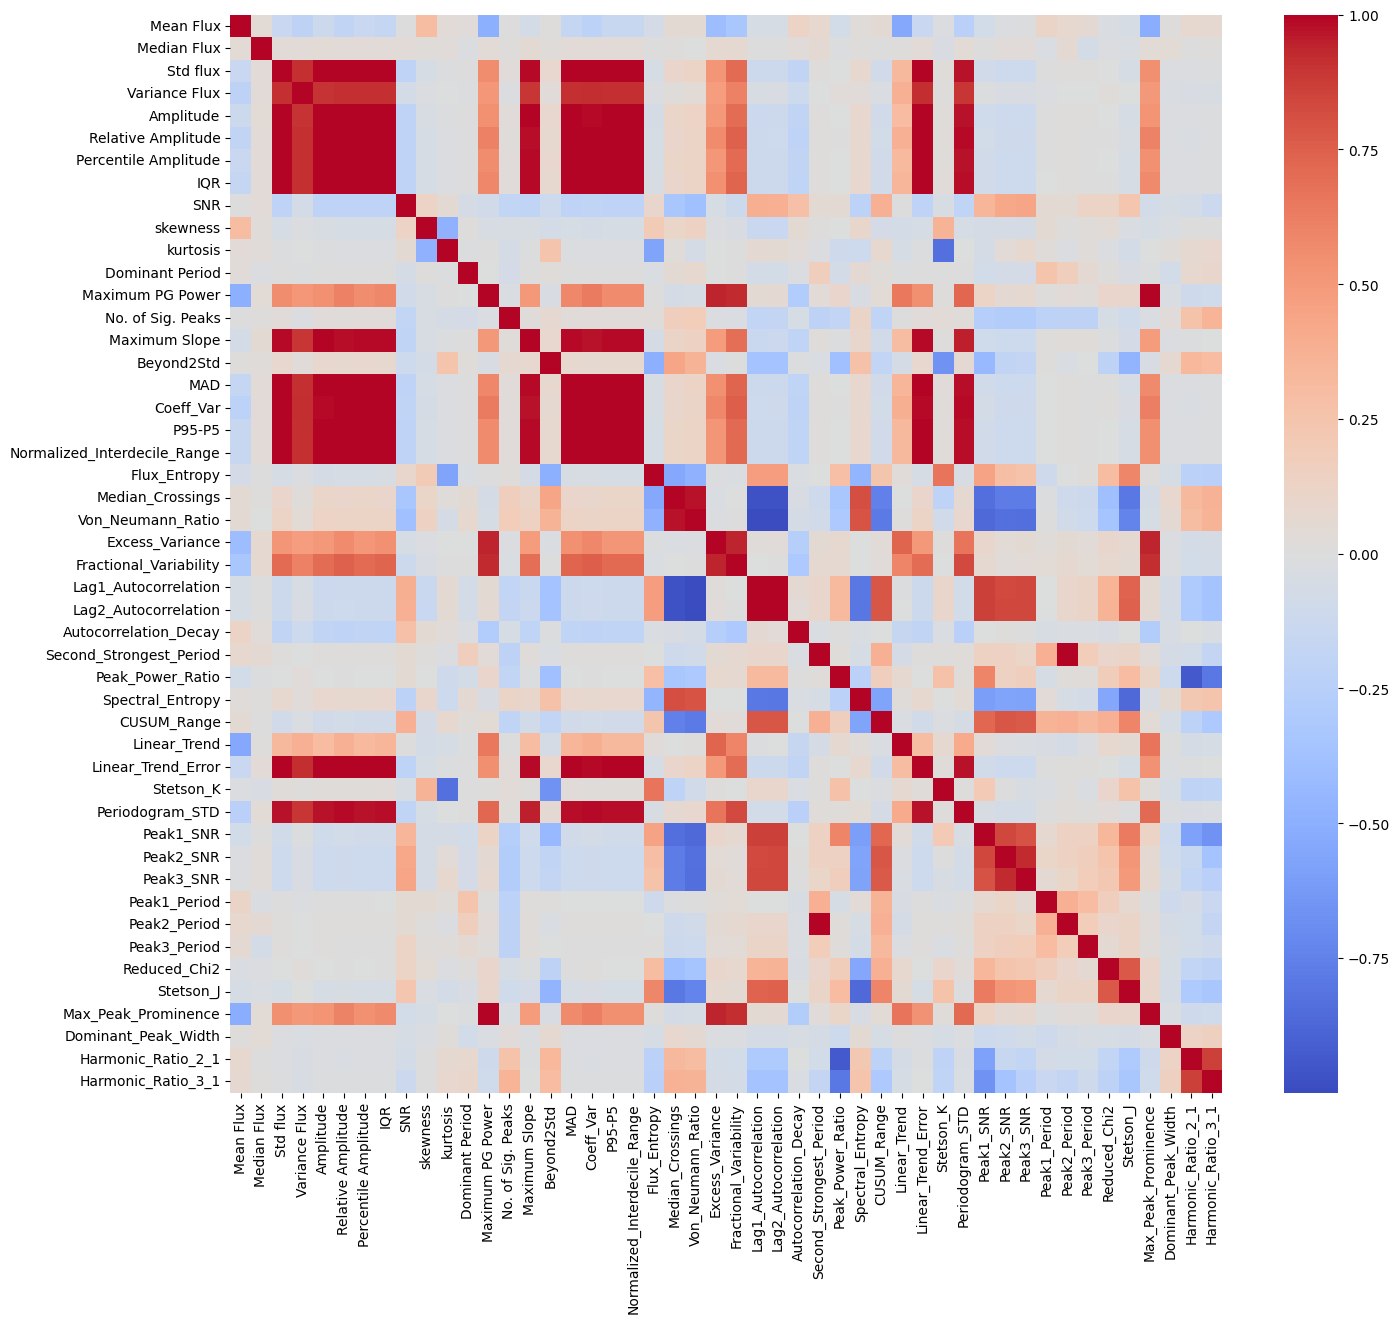

In [ ]:
# Correlation heatmap of the extracted feature matrix:
plt.figure(figsize=(16,14))
sns.heatmap(feature_matrix.corr(),
            cmap="coolwarm",
            center=0)

## **Part 3 - Implementation of selected unsupervised machine learning algorithms**

### **Part 3a - Isolation Forest and SHAP**

#### Implementation of Isolation Forest

Isolation Forest is an unsupervised ensemble-based anomaly detection algorithm that identifies anomalous observations by isolating them from the rest of the data. Unlike density-based or distance-based anomaly detection methods, Isolation Forest does not explicitly model the distribution of normal observations. Instead, it isolates observations through recursive random partitioning.

The anomaly score formula for a data point x in an Isolation Forest is:

$$s(x,n) = 2^{-E(h(x)) / c(n)}$$

Where $E(h(x))$ is the average path length of observation x across all isolation trees, and $c(n)$ is a normalization constant corresponding to the expected path length of a binary search tree containing $n$ observations.

On a more intuitive note, we start with all objects/instances in the root node. Next, a feature is chosen at random, and a split value is chosen (at random) within the range of values that the feature has. The split partitions the data into two groups according to whether their feature values lie above or below the chosen threshold. This process is repeated recursively until each leaf node contains a single observation or the tree reaches its stopping criterion.

The key idea is that if an object has a short path, then it is more likely to be an anomaly, since it means it was easier to separate it from the rest of the data using this random split process. Since a single random tree may isolate some normal observations early by chance, Isolation Forest averages the path lengths over many randomly constructed trees to produce a robust anomaly score.

In this project, the extracted light-curve features are treated as input observations.


The feature matrix is first standardized using StandardScaler to ensure every feature has the same numerical scale, so that no single feature dominates purely because of its magnitude or units. This is achieved by subtracting the mean and dividing by the standard deviation of the feature.

An Isolation Forest model is then trained on the standardized feature matrix. The model assigns each star an anomaly label and an anomaly score.

An anomaly label of +1 indicates that the object was classified as normal, while a label of -1 indicates that it is classified as anomalous. he anomaly score provides a relative measure of how unusual each observation is, with lower scores corresponding to more anomalous stars.

In [ ]:
# Using StandardScaler the standardize the feature matrix:
# More precisely, standardize all features to zero mean and unit variance
std_scaler = StandardScaler()
feature_matrix_scaled = std_scaler.fit_transform(feature_matrix)

cont_frac = 0.1 #Fraction of our instances, that we want to label as anomalies.
iso_for = IsolationForest(n_estimators=100, contamination=cont_frac,random_state=28042005)
#n_estimators -> How many isolation trees should be built
#random_state -> Seed controlling the randomness of the algorithm. Setting a fixed random_state ensures reproducible results across multiple runs.
#contamination -> The fraction of all our instances that we want to be labelled as anomalies. i.e 0.1 means 10% of instances as anomalies.

# Builds the isolation trees and learns the structure of the feature space from the dataset:
iso_for.fit(feature_matrix_scaled)

#Relative to the structure that was learned using iso.fit, a prediction is done
# Whether each star is normal (+1) or anomalous (-1)
labels = iso_for.predict(feature_matrix_scaled)

#A quantity that gives a relative scale of comparison between the anomalies:
# Lower score = more anomalous
# Higher score = more normal
scores = iso_for.decision_function(feature_matrix_scaled)

#Store the anomaly labels and anomaly scores in the feature table, as new columns:
df["Anomaly"] = labels
df["Anomaly_Score"] = scores

#Just to check whether the new columns has been added correctly:
df

,TIC ID,Sector,Mean Flux,Median Flux,Std flux,Variance Flux,Amplitude,Relative Amplitude,Percentile Amplitude,IQR,...,Peak2_Period,Peak3_Period,Reduced_Chi2,Stetson_J,Max_Peak_Prominence,Dominant_Peak_Width,Harmonic_Ratio_2_1,Harmonic_Ratio_3_1,Anomaly,Anomaly_Score
0,7584049,40,1.000145,1.0,0.003615,0.000013,0.026760,0.026756,0.011899,0.004856,...,0.787749,0.927678,12.718521,2.510649,0.003033,5.716580,0.755310,0.549837,1,0.044697
1,7584971,40,1.000182,1.0,0.002485,0.000006,0.020410,0.020406,0.009005,0.002383,...,10.846693,4.700233,8.720983,1.618380,0.001744,8.693862,0.545701,0.494246,1,0.030661
2,7675859,40,1.000231,1.0,0.280802,0.078850,2.623336,2.622730,0.923995,0.373011,...,0.004122,4.700233,1.008850,0.013349,0.017724,6.016268,0.522240,0.508211,1,0.084553
3,7686889,40,0.999886,1.0,0.002222,0.000005,0.016831,0.016833,0.007431,0.003059,...,4.548612,3.357309,6.885319,1.719518,0.001833,6.182858,0.989501,0.582285,1,0.047088
4,7695147,40,0.999824,1.0,0.049664,0.002467,0.440533,0.440611,0.163223,0.066595,...,4.406477,2.203238,1.088942,0.010859,0.001565,6.538051,0.870285,0.864159,1,0.115649
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978,1884383502,40,1.003256,1.0,0.635705,0.404121,5.780080,5.761320,2.083237,0.851124,...,1.566783,3.357392,0.971442,0.008812,0.035182,5.012724,0.881649,0.785656,1,0.072304
979,1884597797,40,1.000138,1.0,0.143867,0.020698,1.331475,1.331291,0.473814,0.192370,...,11.750822,5.222587,1.038708,0.002778,0.006488,5.218136,0.671460,0.659109,1,0.107878
980,1920376931,40,1.001655,1.0,0.695079,0.483135,6.551703,6.540880,2.287334,0.933611,...,5.036076,2.043625,0.989996,0.007388,0.023899,5.256865,0.998807,0.969792,1,0.071974
981,1981699530,40,0.999277,1.0,0.406330,0.165104,3.850955,3.853743,1.336598,0.542496,...,3.811094,1.584387,1.087758,0.005850,0.013924,2.182551,0.978720,0.933800,1,0.046230


A contamination value of 0.1 was chosen so that approximately the most anomalous 10% of observations would be flagged for further investigation. This parameter does not imply that exactly 10% of the stars are truly anomalous. Rather, it controls the fraction of objects returned by the Isolation Forest algorithm.

In this project, the top 10 anomaly candidates (i.e those with the lowest anomaly scores) are selected for detailed analysis.


In [ ]:
# Creating a DataFrame that contains the objects classified as anomalies only:
official_anomalies = df[df["Anomaly"] == -1]
# Creating a DataFrame that contains the objects classified as normal only:
normal_objects = df[df["Anomaly"] == +1]

print("\nThe anomalies are:")
display(official_anomalies)

print("----------------------------------------\n")

# Ranking all observations by anomaly score (lowest score = most anomalous) and picking the top 10
top_ano = 10
score_top_anomalies = df.sort_values("Anomaly_Score").head(top_ano)

print(f"Top {top_ano} anomaly candidates:")
display(score_top_anomalies)

#These two ways allow us to not lose any information about the predicted anomalies.
# The anomaly labels identify all objects classified as anomalous,
# while the anomaly scores provide a ranking of their degree of anomalousness.


The anomalies are:


,TIC ID,Sector,Mean Flux,Median Flux,Std flux,Variance Flux,Amplitude,Relative Amplitude,Percentile Amplitude,IQR,...,Peak2_Period,Peak3_Period,Reduced_Chi2,Stetson_J,Max_Peak_Prominence,Dominant_Peak_Width,Harmonic_Ratio_2_1,Harmonic_Ratio_3_1,Anomaly,Anomaly_Score
22,21487028,40,1.016928,1.0,1.379652,1.903441,13.144674,12.925859,4.468386,1.694019,...,2.937711,5.036076,1.832309,0.207874,0.401905,5.222842,0.794873,0.786226,-1,-0.121960
24,21966634,40,1.012886,1.0,0.953697,0.909537,9.294010,9.175771,3.112438,1.264338,...,7.421594,4.862423,1.629695,0.054869,0.180320,5.428740,0.876155,0.489968,-1,-0.024516
39,24261156,40,1.013379,1.0,1.290285,1.664834,12.783907,12.615127,4.168579,1.668099,...,4.548620,2.711677,6.124147,0.104214,0.233609,6.800592,0.526271,0.493451,-1,-0.088836
41,24341835,40,1.004697,1.0,11.010253,121.225660,102.322395,101.843990,36.224876,13.944679,...,1.855394,1.719634,1.025104,0.009745,0.956356,5.448804,0.673780,0.430960,-1,-0.278870
50,27007746,40,1.000443,1.0,0.004767,0.000023,0.028552,0.028539,0.015246,0.007610,...,17.626313,5.875438,34.548420,4.545549,0.005466,6.169990,0.310997,0.233071,-1,-0.026087
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
971,1881471898,40,1.004533,1.0,1.189863,1.415773,10.199131,10.153111,3.919464,1.589777,...,0.103684,5.423492,1.004953,0.006578,0.091251,5.908779,0.710515,0.472705,-1,-0.004367
972,1881706041,40,0.958094,1.0,11.624310,135.124590,110.630890,115.469790,38.196194,15.454985,...,2.073689,0.613091,1.037501,0.012064,0.856929,5.619682,0.544687,0.542203,-1,-0.280918
975,1882816677,40,1.095337,1.0,5.436944,29.560362,54.153183,49.439762,17.507790,6.916692,...,4.862436,7.421613,16.772340,0.137160,0.872364,6.800560,0.828371,0.635108,-1,-0.252345
976,1882977987,40,1.046503,1.0,1.314214,1.727159,11.438774,10.930469,4.308836,1.753931,...,15.667785,7.050503,2.911150,0.295803,0.603971,5.947880,0.720603,0.451999,-1,-0.125307


----------------------------------------

Top 10 anomaly candidates:


,TIC ID,Sector,Mean Flux,Median Flux,Std flux,Variance Flux,Amplitude,Relative Amplitude,Percentile Amplitude,IQR,...,Peak2_Period,Peak3_Period,Reduced_Chi2,Stetson_J,Max_Peak_Prominence,Dominant_Peak_Width,Harmonic_Ratio_2_1,Harmonic_Ratio_3_1,Anomaly,Anomaly_Score
757,406533735,40,0.745617,1.0,9.683170,93.763780,83.700485,112.256710,31.105787,13.937395,...,6.409569,3.916959,83.092000,3.992961,10.118936,5.792306,0.340055,0.304892,-1,-0.340230
921,1550453189,40,1.061863,1.0,5.692697,32.406796,56.579150,53.282894,18.518070,7.401103,...,23.501300,10.846754,8.322632,0.284470,1.665952,5.379317,0.773290,0.621926,-1,-0.291009
972,1881706041,40,0.958094,1.0,11.624310,135.124590,110.630890,115.469790,38.196194,15.454985,...,2.073689,0.613091,1.037501,0.012064,0.856929,5.619682,0.544687,0.542203,-1,-0.280918
41,24341835,40,1.004697,1.0,11.010253,121.225660,102.322395,101.843990,36.224876,13.944679,...,1.855394,1.719634,1.025104,0.009745,0.956356,5.448804,0.673780,0.430960,-1,-0.278870
910,1400733644,40,1.016180,1.0,5.214062,27.186447,51.708595,50.885265,16.922995,6.892005,...,2.764840,10.846680,13.334465,0.469422,2.254609,5.633977,0.475763,0.461357,-1,-0.273077
949,1717025833,40,0.992976,1.0,11.817824,139.660980,103.714340,104.448006,38.793674,15.466044,...,2.518033,5.423456,1.080856,0.005092,0.626391,6.802357,0.986402,0.887360,-1,-0.264772
975,1882816677,40,1.095337,1.0,5.436944,29.560362,54.153183,49.439762,17.507790,6.916692,...,4.862436,7.421613,16.772340,0.137160,0.872364,6.800560,0.828371,0.635108,-1,-0.252345
963,1859153737,40,0.952036,1.0,1.700925,2.893145,13.219194,13.885191,5.408288,2.680176,...,3.525266,2.611308,14.801949,2.958647,2.032086,5.669641,0.457567,0.308550,-1,-0.246547
911,1400773519,40,1.021154,1.0,8.044184,64.708890,76.941040,75.347176,26.499477,10.592350,...,2.937633,3.615548,1.008339,0.010834,0.770162,6.231505,0.778765,0.581995,-1,-0.226795
938,1712396254,40,0.956255,1.0,6.478326,41.968704,63.017730,65.900580,21.299332,8.491666,...,11.750758,3.916919,1.069969,0.001612,0.378293,5.835098,0.518099,0.426356,-1,-0.197923


Below is a plot that shows the distribution of the anomaly scores assigned by Isolation Forest.


/tmp/ipykernel_4370/4218419681.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


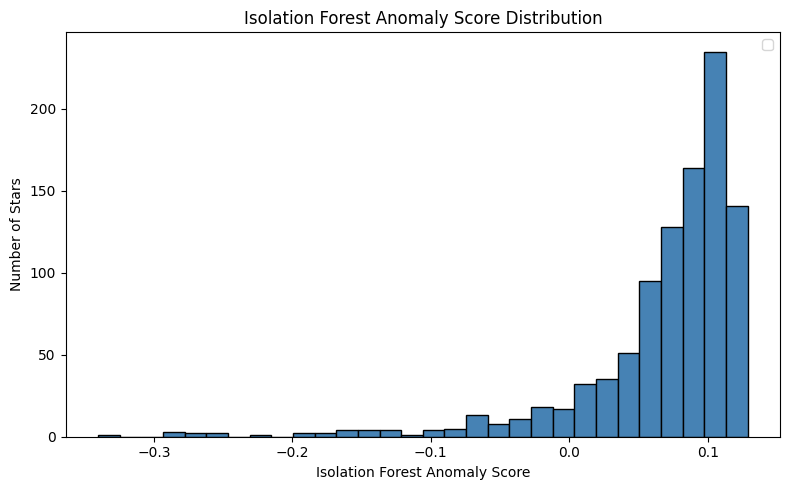

In [ ]:
# Anomaly Score Distrubution:
plt.figure(figsize=(8,5))

plt.hist(df["Anomaly_Score"], bins=30,
         color="steelblue", edgecolor="black")

plt.xlabel("Isolation Forest Anomaly Score")
plt.ylabel("Number of Stars")
plt.title("Isolation Forest Anomaly Score Distribution")

plt.legend()

plt.tight_layout()
plt.show()

To visualize the high-dimensional feature space, the standardized feature matrix is projected onto two principal components using Principal Component Analysis (PCA) below. Each point represents an object/star, while the colors correspond to the anomaly labels assigned by the Isolation Forest model.
* red points = anomalous
* blue points = normal

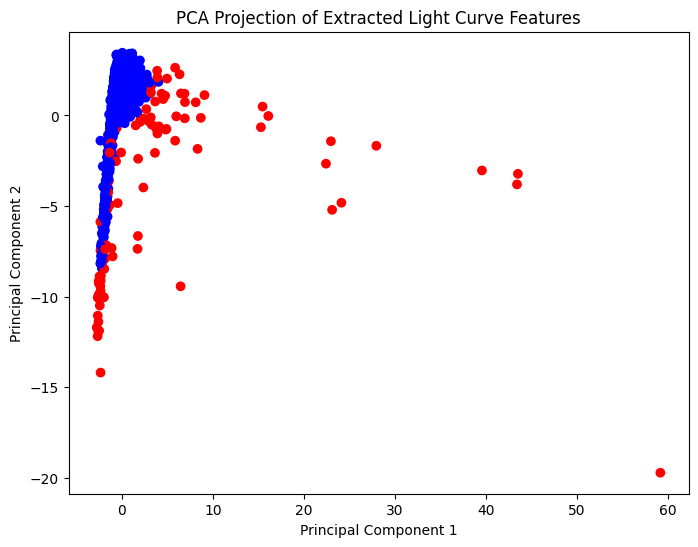

In [ ]:
#PCA Projection of Extracted light curves:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(feature_matrix_scaled)

colors = np.where(df["Anomaly"] == -1, "red", "blue")

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=colors)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Projection of Extracted Light Curve Features")
plt.show()

#### SHAP  - Shapley Additive exPlanations

Before implementing SHAP, it is useful to develop an intuitive understanding of how it works rather than focusing on its mathematical formulation.  SHAP (SHapley Additive exPlanations) is based on Shapley values from cooperative game theory. In a cooperative game, players work together and receive a reward. Shapley values determine how much each player contributed to the final reward.

SHAP treats each feature as a player in a cooperative game and the model's prediction as the reward. The Shapley value assigned to each feature represents its contribution toward the final prediction. These contributions are indicated by:

* Positive SHAP values → Contributes more strongly toward the object being identified as anomalous.

* Negative SHAP values → Contributes toward the object appearing more similar to normal observations.

The sum of all SHAP values explains how the model arrived at its final prediction.

In essence, Isolation Forest identifies which objects are anomalous, and SHAP tells us which extracted features made it anomalous.

In [ ]:
#Just to check if the numbers are right:
print(len(normal_objects))

#Considering a sample of instances that were classified as Normal/Non-anomalous:
#Considering 50 percentage of the objects that were classified as normal, for background training.
normal_samples_df = normal_objects.sample(int(0.50 * len(normal_objects)), random_state=28042005)

#The dataframes we have created till now have TIC ID, Anomaly and Anomaly Scores as columns.
#But for SHAP, what we need to feed in, is the feature matrix/table i.e without TIC ID, Anomaly and Anomaly Scores Columns.
#Since we already have created the whole feature space, we can simply now take the indices of the normal and anomalous objects.
#And use it to create two subsets that consist of the feature spaces of the normal and anomalous objects separately.
normal_index = normal_samples_df.index # We're not taking all normal instances, but just a sample of it for SHAP

top_anomalies = official_anomalies.sort_values("Anomaly_Score").head(top_ano)
anomaly_index = top_anomalies.index

feature_matrix_normalobj = feature_matrix_scaled[normal_index]
feature_matrix_anomalyobj = feature_matrix_scaled[anomaly_index]

#Just to check if the numbers are right:
print(feature_matrix_normalobj.shape)
print(feature_matrix_anomalyobj.shape)

884
(442, 48)
(10, 48)


The resulting SHAP summary plot ranks the features according to their overall importance and illustrates how strongly each feature influenced the anomaly predictions.


  0%|          | 0/10 [00:00<?, ?it/s]

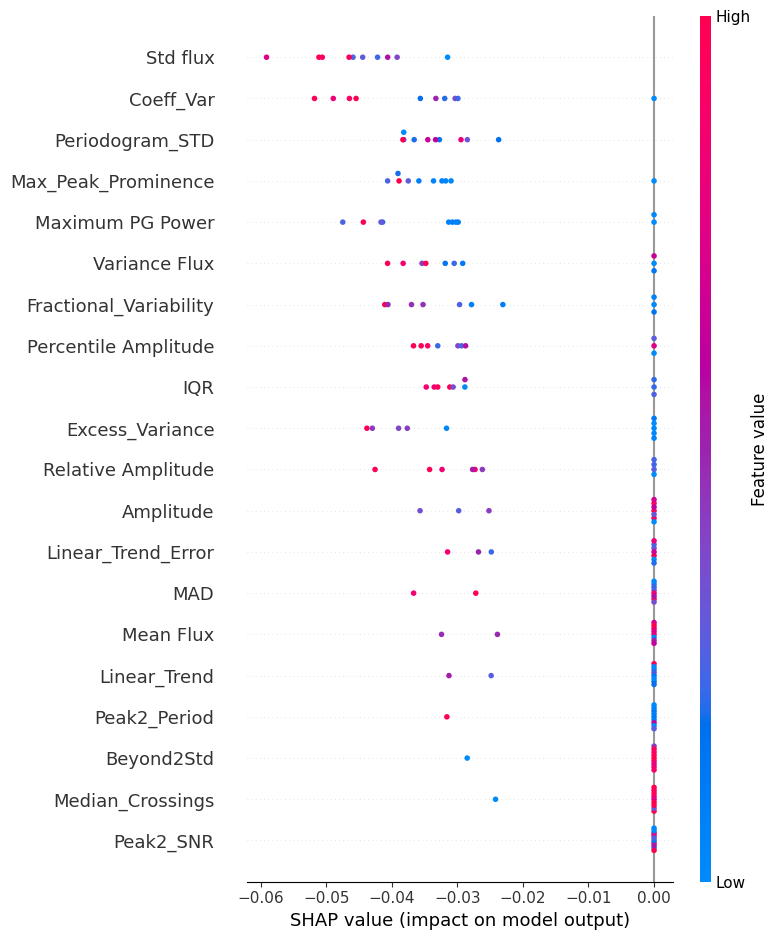

(10, 48)


In [ ]:
# A KernelExplainer is constructed using a sample of the normal stars as the reference population
# SHAP then computes the contribution of each extracted feature toward anomaly prediction
#for the selected anomalous stars
explainer = shap.KernelExplainer(iso_for.decision_function,feature_matrix_normalobj)

# Computing SHAP values for the selected anomalous stars:
shap_values = explainer.shap_values(feature_matrix_anomalyobj)

#Extracting all the feature name from our feature_matrix:
feature_names = feature_matrix.columns

#Creating a SHAP Summary Plot which shows which features contributed most strongly to anomaly detection:
shap.summary_plot(shap_values,feature_matrix_anomalyobj,feature_names=feature_names)
# The feature mentioned on the top row has the most significant effect on the anomalies
# The feature mentioned on the bottom row has the least significance
#Each row has n dots, where n is the number of anomalies (which we set earlier)


#Just to check if the numbers are right:
print(shap_values.shape)

Features are ordered from most important (top) to least important (bottom) according to their contribution to the anomaly predictions. Each point represents one anomalous star. Certain features being near the bottom is an indication that they have little influence on the decisions made by the Isolation Forest in selecting the anomaly candidates.

While the SHAP Summary plot offers a minimal, global explanation, ot obtain a local explanation for each top anomaly candidate, a SHAP waterfall plot is generated.



Rank #1
TIC ID: TIC 406533735
Score: -0.3402


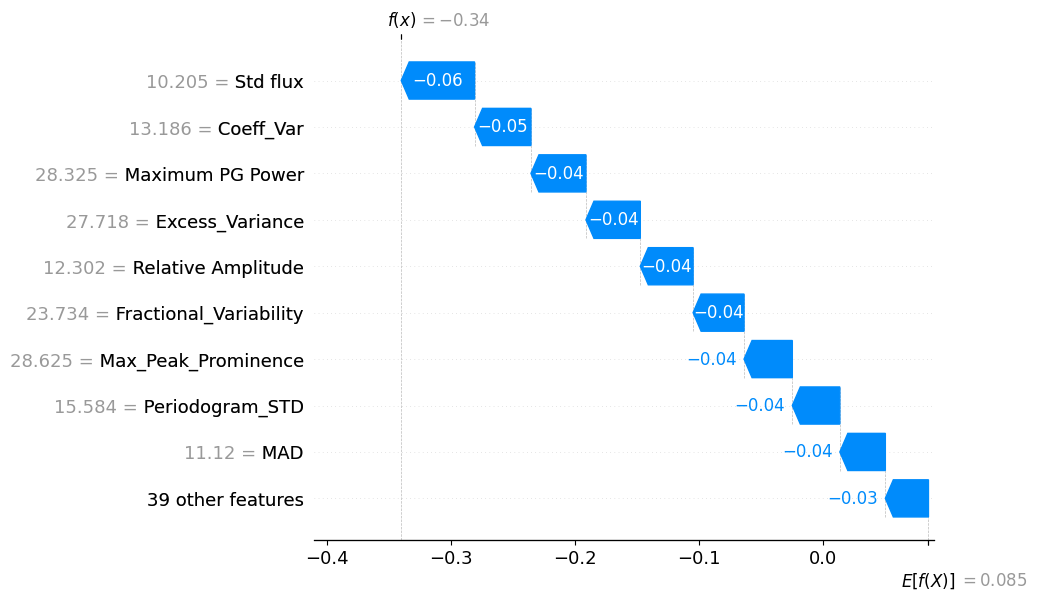


Rank #2
TIC ID: TIC 1550453189
Score: -0.2910


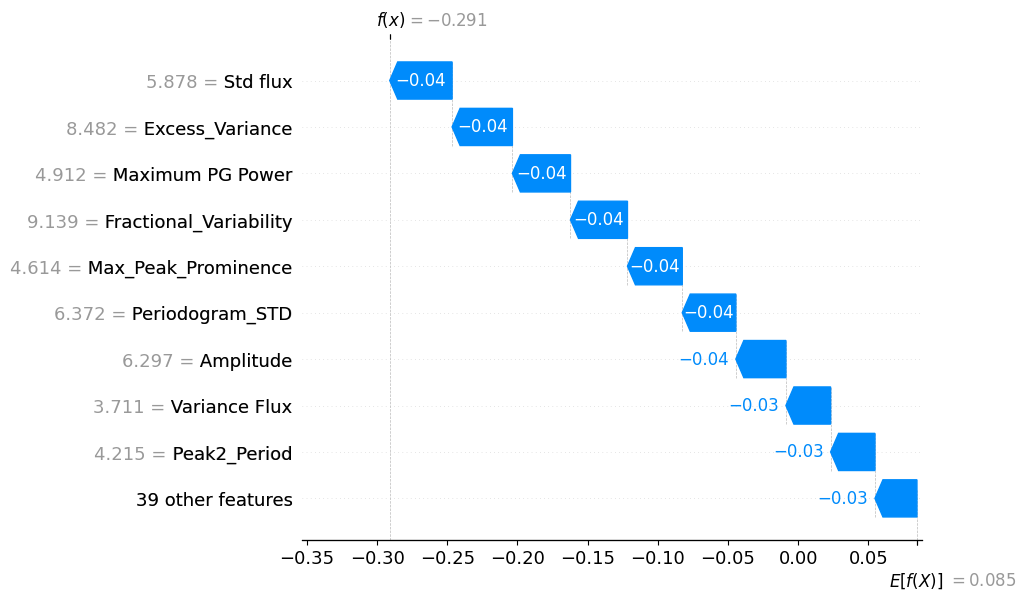


Rank #3
TIC ID: TIC 1881706041
Score: -0.2809


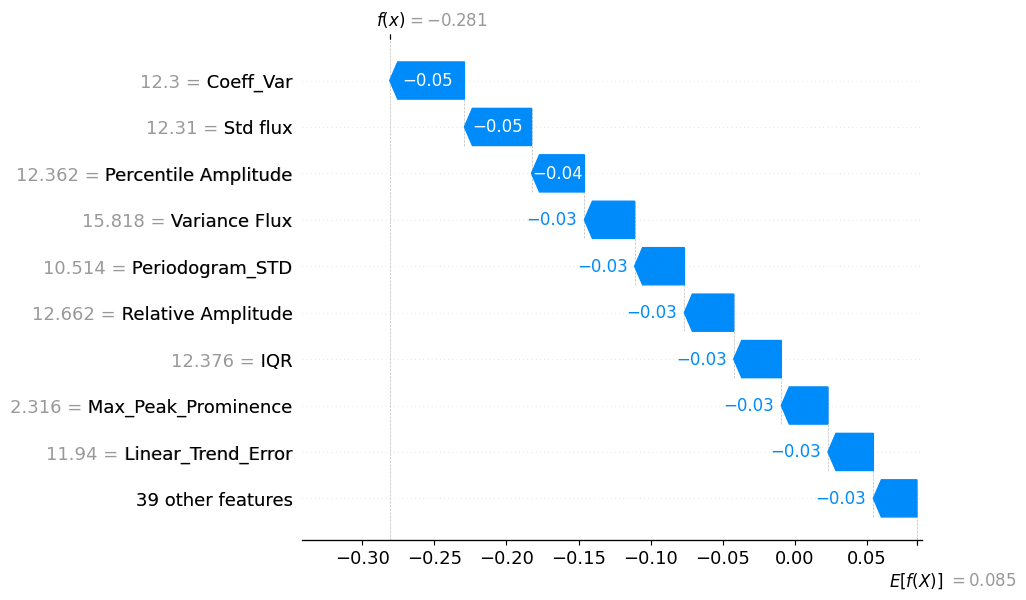


Rank #4
TIC ID: TIC 24341835
Score: -0.2789


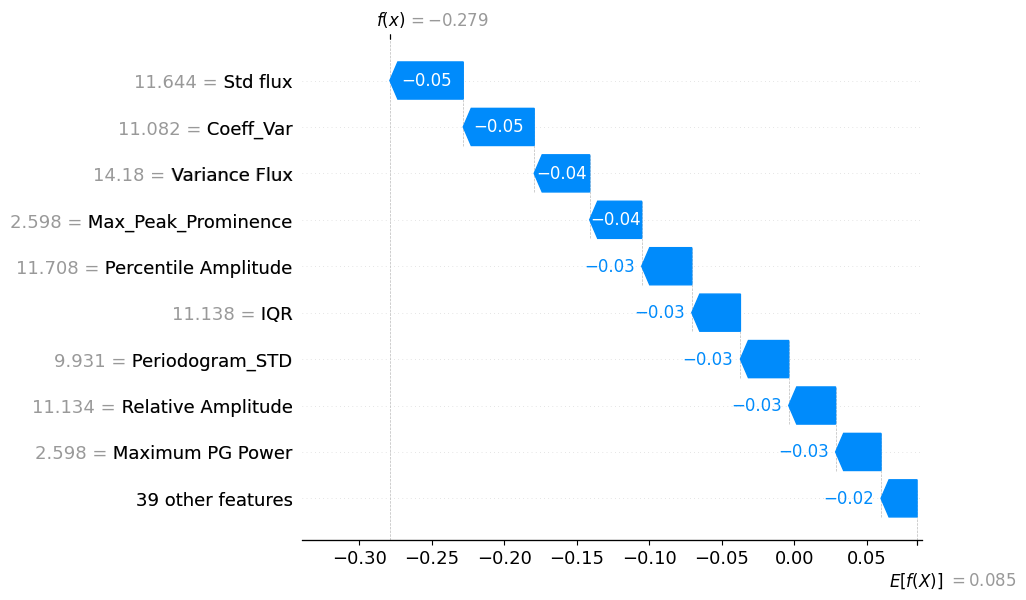


Rank #5
TIC ID: TIC 1400733644
Score: -0.2731


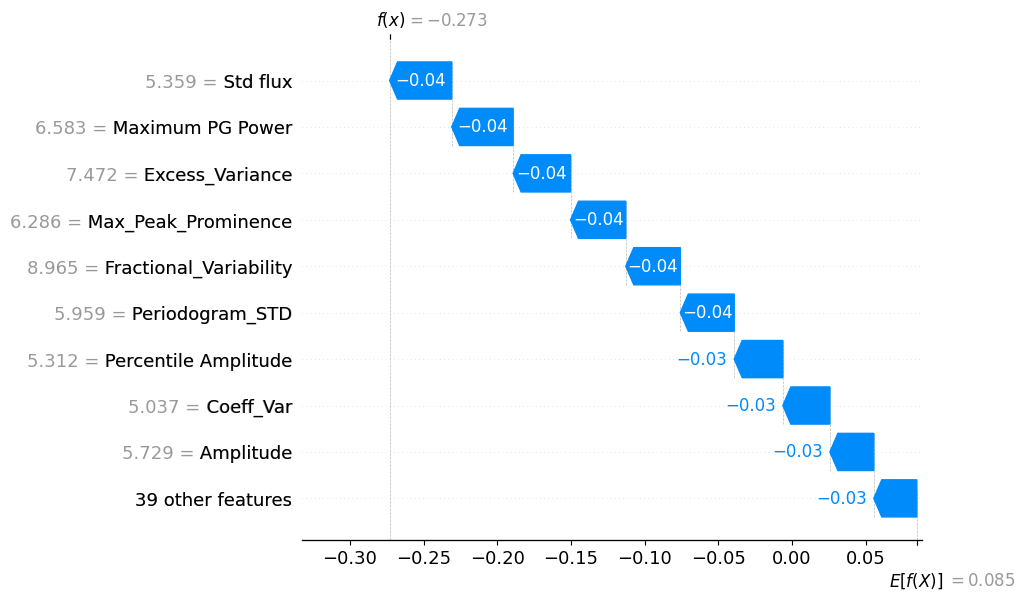


Rank #6
TIC ID: TIC 1717025833
Score: -0.2648


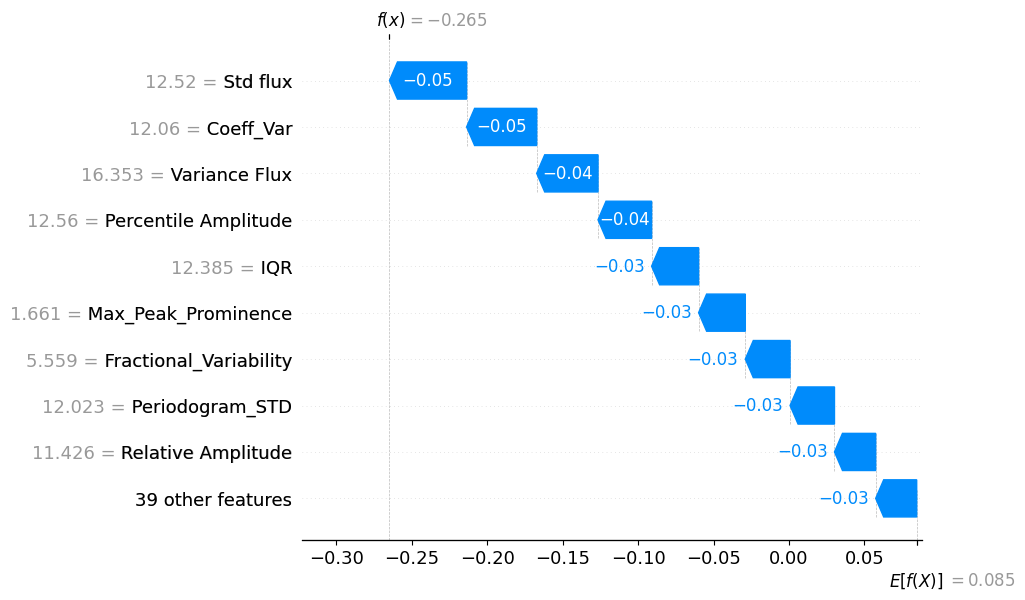


Rank #7
TIC ID: TIC 1882816677
Score: -0.2523


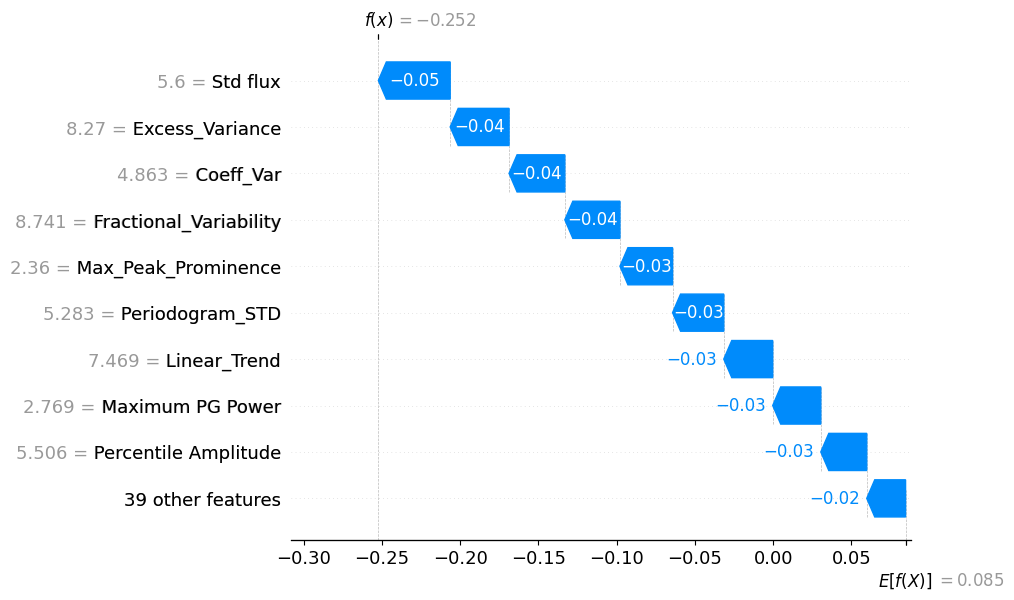


Rank #8
TIC ID: TIC 1859153737
Score: -0.2465


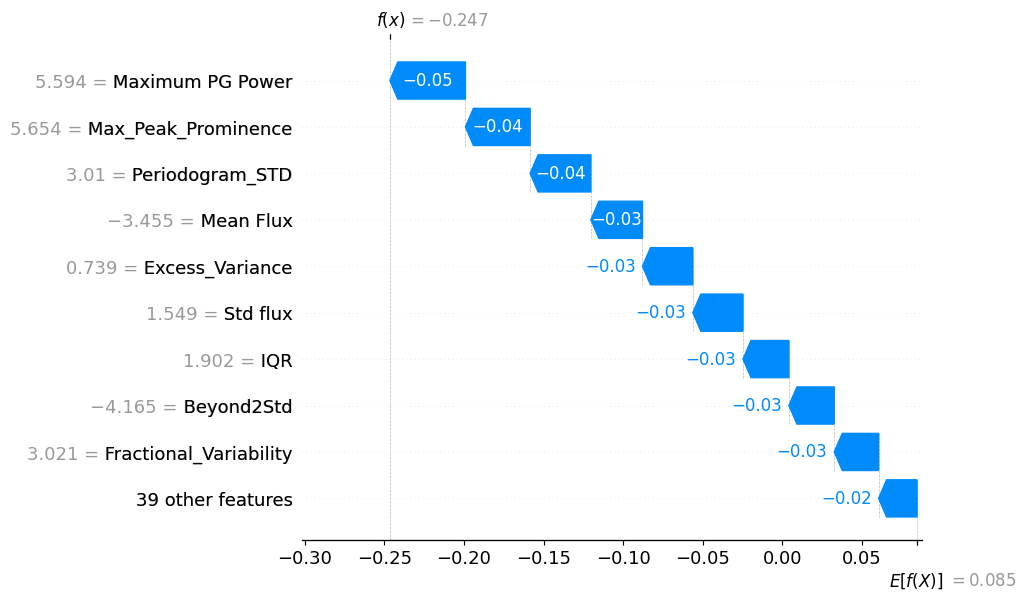


Rank #9
TIC ID: TIC 1400773519
Score: -0.2268


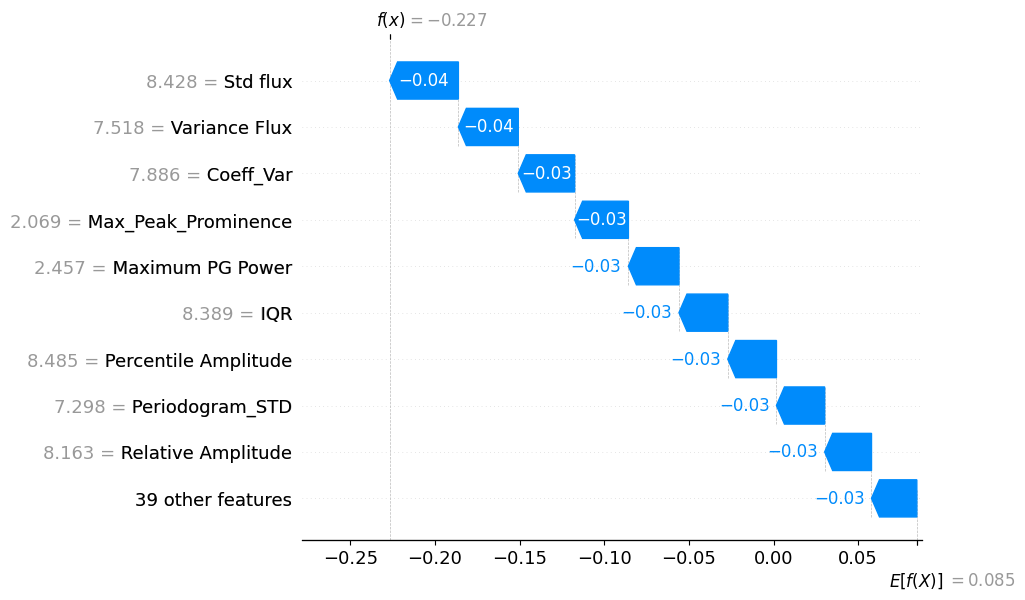


Rank #10
TIC ID: TIC 1712396254
Score: -0.1979


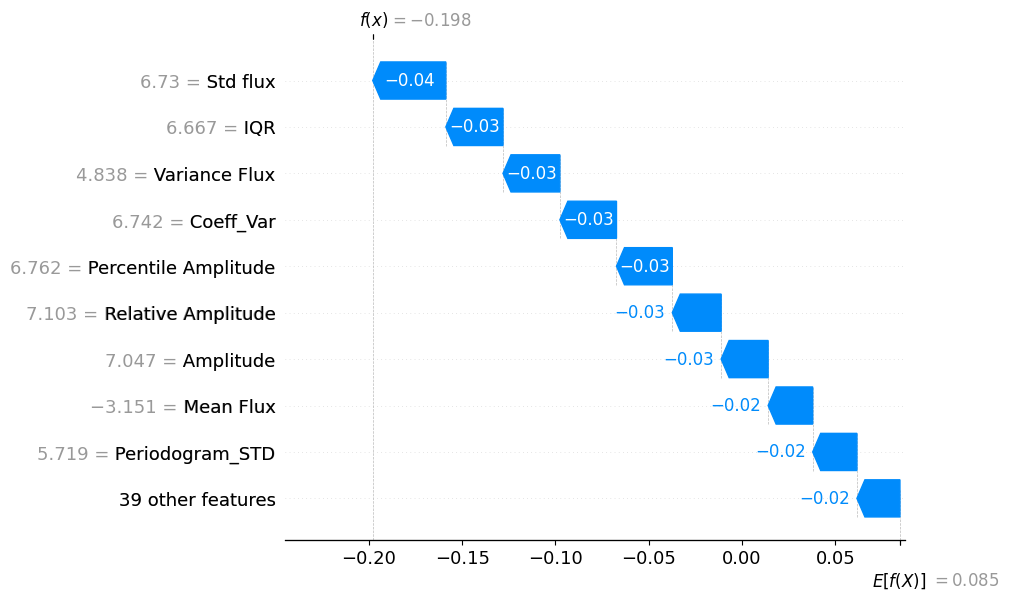

In [ ]:
# Generating a SHAP waterfall plot for a selected anomaly candidate:
def plot_waterfall(anomaly_position):
    explanation = shap.Explanation( values=shap_values[anomaly_position],
                                   base_values=explainer.expected_value,
                                    data=feature_matrix_anomalyobj[anomaly_position],
                                   feature_names=feature_names)

    shap.plots.waterfall(explanation)

num_of_plots = len(top_anomalies)

for i in range(num_of_plots):

    print("\n================================")
    print(f"Rank #{i+1}")
    print(
        f"TIC ID: TIC {int(top_anomalies.iloc[i]['TIC ID'])}"
    )
    print(
        f"Score: {top_anomalies.iloc[i]['Anomaly_Score']:.4f}"
    )
    print("================================")

    plot_waterfall(i)

The features mentioned higher up on the y-axis of the individual plots indicate their significant roles in that particular star being classified as anomalous.


#### Visual Inspection of the top anomaly candidates - Results of Isolation Forest



In [ ]:
# Printing a table consisting of just the top anomalies:
final_table = top_anomalies.sort_values("Anomaly_Score")

#Dropping the 'Anomaly' column, since we obviously know that it was classified as an anomaly.
display(final_table.drop(columns=["Anomaly"]))

,TIC ID,Sector,Mean Flux,Median Flux,Std flux,Variance Flux,Amplitude,Relative Amplitude,Percentile Amplitude,IQR,...,Peak1_Period,Peak2_Period,Peak3_Period,Reduced_Chi2,Stetson_J,Max_Peak_Prominence,Dominant_Peak_Width,Harmonic_Ratio_2_1,Harmonic_Ratio_3_1,Anomaly_Score
757,406533735,40,0.745617,1.0,9.683170,93.763780,83.700485,112.256710,31.105787,13.937395,...,4.862432,6.409569,3.916959,83.092000,3.992961,10.118936,5.792306,0.340055,0.304892,-0.340230
921,1550453189,40,1.061863,1.0,5.692697,32.406796,56.579150,53.282894,18.518070,7.401103,...,7.421463,23.501300,10.846754,8.322632,0.284470,1.665952,5.379317,0.773290,0.621926,-0.291009
972,1881706041,40,0.958094,1.0,11.624310,135.124590,110.630890,115.469790,38.196194,15.454985,...,0.307884,2.073689,0.613091,1.037501,0.012064,0.856929,5.619682,0.544687,0.542203,-0.280918
41,24341835,40,1.004697,1.0,11.010253,121.225660,102.322395,101.843990,36.224876,13.944679,...,2.043623,1.855394,1.719634,1.025104,0.009745,0.956356,5.448804,0.673780,0.430960,-0.278870
910,1400733644,40,1.016180,1.0,5.214062,27.186447,51.708595,50.885265,16.922995,6.892005,...,3.204701,2.764840,10.846680,13.334465,0.469422,2.254609,5.633977,0.475763,0.461357,-0.273077
949,1717025833,40,0.992976,1.0,11.817824,139.660980,103.714340,104.448006,38.793674,15.466044,...,4.028853,2.518033,5.423456,1.080856,0.005092,0.626391,6.802357,0.986402,0.887360,-0.264772
975,1882816677,40,1.095337,1.0,5.436944,29.560362,54.153183,49.439762,17.507790,6.916692,...,14.101065,4.862436,7.421613,16.772340,0.137160,0.872364,6.800560,0.828371,0.635108,-0.252345
963,1859153737,40,0.952036,1.0,1.700925,2.893145,13.219194,13.885191,5.408288,2.680176,...,3.000226,3.525266,2.611308,14.801949,2.958647,2.032086,5.669641,0.457567,0.308550,-0.246547
911,1400773519,40,1.021154,1.0,8.044184,64.708890,76.941040,75.347176,26.499477,10.592350,...,7.833688,2.937633,3.615548,1.008339,0.010834,0.770162,6.231505,0.778765,0.581995,-0.226795
938,1712396254,40,0.956255,1.0,6.478326,41.968704,63.017730,65.900580,21.299332,8.491666,...,7.421531,11.750758,3.916919,1.069969,0.001612,0.378293,5.835098,0.518099,0.426356,-0.197923


Having our top anomaly candidates as classified by Isolation Forest, we can plot their preprocessed light curves for visual inspection and astrophysical interpretation. This allows us to observe whether the detected anomalies exhibit unusual variability, nd to assess whether they are likely to represent genuine astrophysical phenomena or are instead the result of instrumental artefacts or data quality issues.

The y-axis represents the normalized PDCSAP flux, while the x-axis represents time in Barycentric TESS Julian Date (BTJD).

In [ ]:
# Plotting the preprocessed light curve for each top anomaly candidate:

for tic in top_anomalies["TIC ID"]:
    lc = extract_lightcurve(tic, 40)
    if lc is None:
        continue
    lc_clean = preprocess_lc(lc)
    print(f"TIC {tic}")
    lc_clean.scatter(alpha=0.5,s=2)

Skipping TIC TIC 406533735: HTTPSConnectionPool(host='mast.stsci.edu', port=443): Max retries exceeded with url: /portal/Mashup/Mashup.asmx/columnsconfig (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7b1acad12960>: Failed to establish a new connection: [Errno 113] No route to host'))
Skipping TIC TIC 1550453189: HTTPSConnectionPool(host='mast.stsci.edu', port=443): Max retries exceeded with url: /portal/Mashup/Mashup.asmx/columnsconfig (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7b1acafcdca0>: Failed to establish a new connection: [Errno 113] No route to host'))
Skipping TIC TIC 1881706041: HTTPSConnectionPool(host='mast.stsci.edu', port=443): Max retries exceeded with url: /portal/Mashup/Mashup.asmx/columnsconfig (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7b1aca48ddf0>: Failed to establish a new connection: [Errno 113] No route to host'))
Skipping TIC TIC 24341835: HTTPSConnectionPo

Now, we plot their phase-folded light curves; each anomaly candidate is phase-folded using its dominant period to determine whether its variability is periodic. By overlaying multiple cycles onto a single phase, the recurring patterns (if any) become easier to identify visually.


In [ ]:
for tic in top_anomalies["TIC ID"]:
    lc = extract_lightcurve(tic, 40)
    if lc is None:
        continue
    lc_clean = preprocess_lc(lc)
    print(f"TIC {tic}")
    # Read the period from your features table
    period_pg_ano = df.loc[df["TIC ID"] == tic, "Dominant Period"].values[0]
    folded = lc_clean.fold(period=period_pg_ano,normalize_phase=True)
    folded.scatter()

Skipping TIC TIC 406533735: HTTPSConnectionPool(host='mast.stsci.edu', port=443): Max retries exceeded with url: /portal/Mashup/Mashup.asmx/columnsconfig (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7b1aca982870>: Failed to establish a new connection: [Errno 113] No route to host'))
Skipping TIC TIC 1550453189: HTTPSConnectionPool(host='mast.stsci.edu', port=443): Max retries exceeded with url: /portal/Mashup/Mashup.asmx/columnsconfig (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7b1aca34b560>: Failed to establish a new connection: [Errno 113] No route to host'))
Skipping TIC TIC 1881706041: HTTPSConnectionPool(host='mast.stsci.edu', port=443): Max retries exceeded with url: /portal/Mashup/Mashup.asmx/columnsconfig (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7b1aca4a57f0>: Failed to establish a new connection: [Errno 113] No route to host'))
Skipping TIC TIC 24341835: HTTPSConnectionPo

#### Final table of Isolation Forest Results

To investigate whether the detected anomaly candidates have been classified already, and to understand their nature further, each candidate is cross-matched with the SIMBAD astronomical database using its sky coordinates. We extract information such as the object’s identifier, astrophysical classification, and spectral type.

A matching radius of 2 arcseconds is used to identify the corresponding SIMBAD objects, while trying to minimize the chance of incorrect associations as much as possible.

**Note:** Since the cell below establishes network connections to external astronomical databases (MAST and SIMBAD), you may occasionally encounter temporary network or timeout errors. If this occurs, please wait a moment and try re-executing the cell.


In [ ]:
# Configuring the SIMBAD query to return additional object information:
customSimbad = Simbad()
customSimbad.add_votable_fields("otype", "otypes", "sp")

catalog_results_IF = []

# Cross verifying/matching each anomaly candidate with the SIMBAD database:
for tic in top_anomalies["TIC ID"]:
    print(f"Searching TIC {tic}")
    tic_result = Catalogs.query_criteria(catalog="TIC", ID=tic)

    if len(tic_result) == 0:
        continue

    ra = tic_result["ra"][0]
    dec = tic_result["dec"][0]

    # Converting the TIC Coordinates into a 'SkyCoord' object, to allow positional matching
    coord = SkyCoord(ra=ra*u.deg, dec=dec*u.deg)

    simbad = customSimbad.query_region(coord, radius=2*u.arcsec)

    if simbad is None or len(simbad) == 0:

        catalog_results_IF.append({ "TIC ID": tic, "RA": ra, "Dec": dec, "Found": False, "Main ID": None, "Object Type": None, "Spectral Type": None})
        continue

    catalog_results_IF.append({"TIC ID": tic, "RA": ra, "Dec": dec, "Found": True, "Main ID": simbad["main_id"][0], "Object Type": simbad["otype"][0], "Spectral Type": simbad["sp_type"][0]})

# Storing the cross-match results in a DataFrame:
catalog_df_IF = pd.DataFrame(catalog_results_IF)
display(catalog_df_IF)

Searching TIC 406533735
Searching TIC 1550453189
Searching TIC 1881706041
Searching TIC 24341835


Searching TIC 1400733644
Searching TIC 1717025833
Searching TIC 1882816677
Searching TIC 1859153737
Searching TIC 1400773519
Searching TIC 1712396254


,TIC ID,RA,Dec,Found,Main ID,Object Type,Spectral Type
0,406533735,311.324372,81.084279,True,BD+80 670B,WD*,DA6.0
1,1550453189,278.831492,39.304651,True,TIC 1550453189,HS?,
2,1881706041,295.827955,47.690941,True,PSO J295.8279+47.6909,HS?,
3,24341835,291.100991,31.935194,False,None,None,None
4,1400733644,266.741333,55.150748,True,Gaia DR3 1418167865786389376,WD*,DA
5,1717025833,289.771594,48.251676,True,PTF1 J191905.19+481506.2,CV*,
6,1882816677,294.811623,48.444801,True,GALEX J193914.7+482641,WD*,DA
7,1859153737,294.690845,26.797737,True,Gaia DR3 2025075641305573888,WD?,
8,1400773519,262.698282,55.755129,True,CRTS J173047.5+554518,CV*,
9,1712396254,287.050134,29.215534,True,PSO J287.0501+29.2155,HS?,


### **Part 3b - Dense Autoencoder**

#### Dense Autoencoder

Autoencoders are a class of artificial neural networks used primarily for unsupervised learning. The main goal of an autoencoder is to learn a compressed or “encoded” representation of data, and reconstruct the original data from this compressed representation.

A typical autoencoder consists of the following components:


1.  Input Layer: Where raw data enters the network

2. Encoder: Compression of the input into a lower-dimensional representation using a series of linear transformations and non-linear activation functions.

3. Latent Space (Bottleneck): Contains the compressed network representation of the input. The size of this layer determines how much information the network is forced to retain.

4. Decoder: Attempts to reconstruct the original input from the compressed representation.

5. Output Layer: Produces the final reconstructed data. The reconstructed output is then compared to the original input to determine how well the network has learned the data’s structure.

This can be used for anomaly detection, as the autoencoder can learn what a normal star looks like. If a star is unusual, the autoencoder cannot reconstruct it well, and thus the reconstruction error will be large. The objects can be ranked based on the reconstruction error, and the ones with the highest reconstruction error would be the anomalies.

To make it clearer, the reconstruction error serves as the anomaly score for the Dense autoencoder, analogous in nature to the anomaly score produced by the Isolation Forest. Here I have implemented a simple autoencoder known as the dense autoencoder.






#### Training the Dense Autoencoder

Rather than training on the entire dataset, the autoencoder is trained only on stars that are most likely to be normal. To obtain such a training set, the anomaly scores produced by the Isolation Forest are used to select a subset of confidently normal stars. Specifically, in my implementation, I have selected only the stars whose anomaly scores lie above the 40th percentile of the normal population. This allows the autoencoder to learn a cleaner representation of normal stellar behaviour.



In [ ]:
# Selecting the most confidently normal stars for training the autoencoder:

threshold = normal_objects["Anomaly_Score"].quantile(0.40)
confident_normals = normal_objects[ normal_objects["Anomaly_Score"] > threshold ]
X_train_scaled = feature_matrix_scaled[confident_normals.index]

The autoencoder is constructed using a series of fully connected (Dense) layers that compress the input features into a lower-dimensional representation before reconstructing them back again.

The Adam optimizer is used to update the network weights during training. EarlyStopping monitors the validation loss to prevent overfitting. When this is used, training is terminated automatically when the validation loss no longer improves, and the model weights corresponding to the lowest validation loss are restored.  

After training, as mentioned earlier, the autoencoder reconstructs all objects in the dataset. The reconstruction error is calculated for each object. Objects/stars with the largest reconstruction errors are considered the strongest anomaly candidates.


In [ ]:
input_dim = X_train_scaled.shape[1]

inputs = Input(shape=(input_dim,))

# ReLu (for activation function) -> Rectified Linear Unit -> Allows the neural network to learn non-linear relationships
# A linear activation is used in the output layer so that reconstructed feature values are not artificially constrained.

encoded = Dense(32, activation="relu")(inputs)
encoded = Dense(16, activation="relu")(encoded)
encoded = Dense(12, activation="relu")(encoded)

decoded = Dense(16, activation="relu")(encoded)
decoded = Dense(32, activation="relu")(decoded)
outputs = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(inputs, outputs)

# The optimizer decides how the weights should change after every mistake (mistake = training loss)
# Loss tells the network how good/bad the reconstruction of the (each) training data was. MSE = Mean Squared Error ; small MSE means good reconstruction.

autoencoder.compile(optimizer="adam", loss="mse")

# epoch -> one complete pass through the entire training dataset. i.e for example: star 1 to star 100
# validation_split -> Keeping aside 20% of the dataset for validation ; 80% of the dataset for training

# Training Loss -> How well is the reconstruction of the stars belonging to the training dataset done (the stars it learned from)?
# Validation Loss -> How well is the reconstruction of the stars belonging to the validation dataset done (the stars it didn't learn from)?

# To prevent overfitting - when the network starts to memorize the training dataset so much, that training loss decreases but validation loss increases
# I use what's known as EarlyStopping to prevent this:
# EarlyStopping stops the model from going onto further epochs, once the lowest validation loss is reached; before it starts increasing again
# Patience -> The number of epochs EarlyStopping will wait, after there's no improvement in the validation loss, before stopping the training

early_stop = EarlyStopping(monitor="val_loss", patience=10, min_delta=1e-3, restore_best_weights=True)

# Training the network using mini-batches of 32 samples each:
history = autoencoder.fit(X_train_scaled, X_train_scaled, epochs=300, batch_size=32, validation_split=0.2, callbacks=[early_stop], verbose=1)

# Reconstructing the complete feature matrix:
feature_mat_predict = autoencoder.predict(feature_matrix_scaled)

# Computing the reconstruction error for every star:
reconstruction_error = np.mean((feature_matrix_scaled - feature_mat_predict)**2, axis=1)

df["Reconstruction_Error"] = reconstruction_error

# Ranking stars by their reconstruction error:
top_anomalies_DAE = df.sort_values( by="Reconstruction_Error", ascending=False)

top10_anomal = top_anomalies_DAE.head(10)

#Just to check whether the new columns has been added correctly:
df

Epoch 1/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.2232 - val_loss: 0.2093
Epoch 2/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2071 - val_loss: 0.1926
Epoch 3/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1866 - val_loss: 0.1733
Epoch 4/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1673 - val_loss: 0.1550
Epoch 5/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1527 - val_loss: 0.1407
Epoch 6/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1404 - val_loss: 0.1279
Epoch 7/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1288 - val_loss: 0.1165
Epoch 8/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1181 - val_loss: 0.1062
Epoch 9/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1081 - val_loss: 0.0969
Epoch 10/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0992 - val_loss: 0.0877
Epoch 11/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0915 - val_loss: 0.0812
Epoch 12/300
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - 

,TIC ID,Sector,Mean Flux,Median Flux,Std flux,Variance Flux,Amplitude,Relative Amplitude,Percentile Amplitude,IQR,...,Peak3_Period,Reduced_Chi2,Stetson_J,Max_Peak_Prominence,Dominant_Peak_Width,Harmonic_Ratio_2_1,Harmonic_Ratio_3_1,Anomaly,Anomaly_Score,Reconstruction_Error
0,7584049,40,1.000145,1.0,0.003615,0.000013,0.026760,0.026756,0.011899,0.004856,...,0.927678,12.718521,2.510649,0.003033,5.716580,0.755310,0.549837,1,0.044697,0.506390
1,7584971,40,1.000182,1.0,0.002485,0.000006,0.020410,0.020406,0.009005,0.002383,...,4.700233,8.720983,1.618380,0.001744,8.693862,0.545701,0.494246,1,0.030661,1.489552
2,7675859,40,1.000231,1.0,0.280802,0.078850,2.623336,2.622730,0.923995,0.373011,...,4.700233,1.008850,0.013349,0.017724,6.016268,0.522240,0.508211,1,0.084553,0.013354
3,7686889,40,0.999886,1.0,0.002222,0.000005,0.016831,0.016833,0.007431,0.003059,...,3.357309,6.885319,1.719518,0.001833,6.182858,0.989501,0.582285,1,0.047088,0.422670
4,7695147,40,0.999824,1.0,0.049664,0.002467,0.440533,0.440611,0.163223,0.066595,...,2.203238,1.088942,0.010859,0.001565,6.538051,0.870285,0.864159,1,0.115649,0.016225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978,1884383502,40,1.003256,1.0,0.635705,0.404121,5.780080,5.761320,2.083237,0.851124,...,3.357392,0.971442,0.008812,0.035182,5.012724,0.881649,0.785656,1,0.072304,0.064197
979,1884597797,40,1.000138,1.0,0.143867,0.020698,1.331475,1.331291,0.473814,0.192370,...,5.222587,1.038708,0.002778,0.006488,5.218136,0.671460,0.659109,1,0.107878,0.008936
980,1920376931,40,1.001655,1.0,0.695079,0.483135,6.551703,6.540880,2.287334,0.933611,...,2.043625,0.989996,0.007388,0.023899,5.256865,0.998807,0.969792,1,0.071974,0.078629
981,1981699530,40,0.999277,1.0,0.406330,0.165104,3.850955,3.853743,1.336598,0.542496,...,1.584387,1.087758,0.005850,0.013924,2.182551,0.978720,0.933800,1,0.046230,1.231688


Below is a plot that shows the evolution of both the training loss and validation loss during training. It provides an indication of how well the autoencoder learned the training data and shows the effects of EarlyStopping.


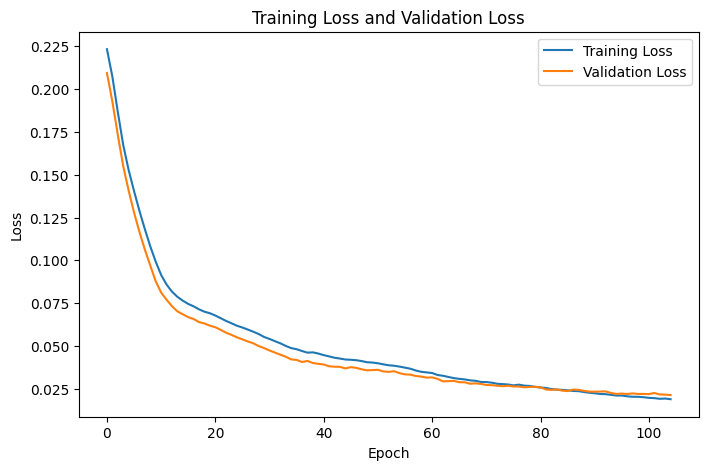

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training Loss and Validation Loss")
plt.show()

#### Reconstruction Error - Distribution and Feature-Wise Analysis

The histogram below shows the distribution of the reconstruction errors across the dataset.

/tmp/ipykernel_4370/1018726150.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


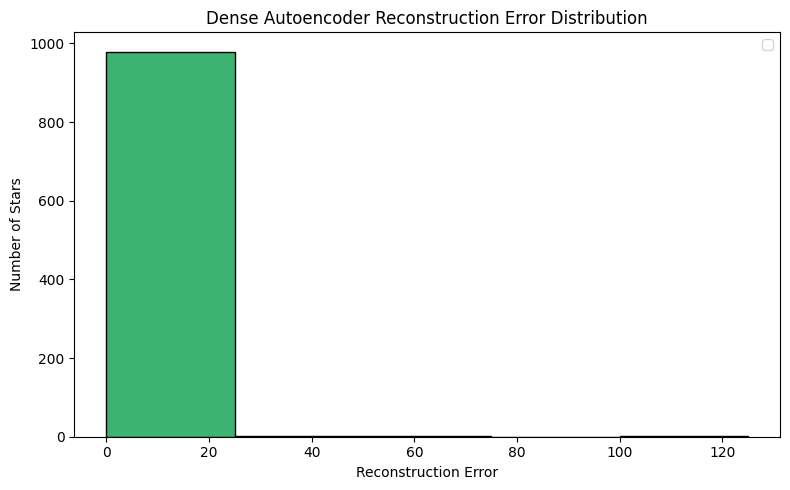

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["Reconstruction_Error"],
         bins=5,
         color="mediumseagreen",
         edgecolor="black")

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Stars")
plt.title("Dense Autoencoder Reconstruction Error Distribution")

plt.legend()

plt.tight_layout()
plt.show()

As seen, there are very few objects that have a high reconstruction error. These are our anomalies. A table of the top 10 anomalies, based on the reconstruction error, is shown below.


In [ ]:
print(f"Top 10 anomaly candidates:")
display(top10_anomal)

Top 10 anomaly candidates:


,TIC ID,Sector,Mean Flux,Median Flux,Std flux,Variance Flux,Amplitude,Relative Amplitude,Percentile Amplitude,IQR,...,Peak3_Period,Reduced_Chi2,Stetson_J,Max_Peak_Prominence,Dominant_Peak_Width,Harmonic_Ratio_2_1,Harmonic_Ratio_3_1,Anomaly,Anomaly_Score,Reconstruction_Error
757,406533735,40,0.745617,1.0,9.683170,93.763780,83.700485,112.256710,31.105787,13.937395,...,3.916959,83.092000,3.992961,10.118936,5.792306,0.340055,0.304892,-1,-0.340230,124.999873
949,1717025833,40,0.992976,1.0,11.817824,139.660980,103.714340,104.448006,38.793674,15.466044,...,5.423456,1.080856,0.005092,0.626391,6.802357,0.986402,0.887360,-1,-0.264772,53.054458
972,1881706041,40,0.958094,1.0,11.624310,135.124590,110.630890,115.469790,38.196194,15.454985,...,0.613091,1.037501,0.012064,0.856929,5.619682,0.544687,0.542203,-1,-0.280918,50.136075
41,24341835,40,1.004697,1.0,11.010253,121.225660,102.322395,101.843990,36.224876,13.944679,...,1.719634,1.025104,0.009745,0.956356,5.448804,0.673780,0.430960,-1,-0.278870,42.227782
911,1400773519,40,1.021154,1.0,8.044184,64.708890,76.941040,75.347176,26.499477,10.592350,...,3.615548,1.008339,0.010834,0.770162,6.231505,0.778765,0.581995,-1,-0.226795,21.921065
942,1715372736,40,0.998247,1.0,0.025005,0.000625,0.311369,0.311916,0.052846,0.019017,...,0.783381,15.759175,1.453969,0.010779,5.452304,0.729747,0.726068,-1,-0.064180,20.106248
921,1550453189,40,1.061863,1.0,5.692697,32.406796,56.579150,53.282894,18.518070,7.401103,...,10.846754,8.322632,0.284470,1.665952,5.379317,0.773290,0.621926,-1,-0.291009,19.972806
975,1882816677,40,1.095337,1.0,5.436944,29.560362,54.153183,49.439762,17.507790,6.916692,...,7.421613,16.772340,0.137160,0.872364,6.800560,0.828371,0.635108,-1,-0.252345,15.471329
910,1400733644,40,1.016180,1.0,5.214062,27.186447,51.708595,50.885265,16.922995,6.892005,...,10.846680,13.334465,0.469422,2.254609,5.633977,0.475763,0.461357,-1,-0.273077,15.444381
938,1712396254,40,0.956255,1.0,6.478326,41.968704,63.017730,65.900580,21.299332,8.491666,...,3.916919,1.069969,0.001612,0.378293,5.835098,0.518099,0.426356,-1,-0.197923,14.893352


Now, for each of the top (10) anomaly candidates, the absolute reconstruction error is computed for each feature. For each anomaly candidate, a plot is created consisting of the features that displayed the largest reconstruction errors.

This provides insight into why a particular star was identified as anomalous. In essence, it does a job analogous to SHAP, which was utilized for Isolation Forest.


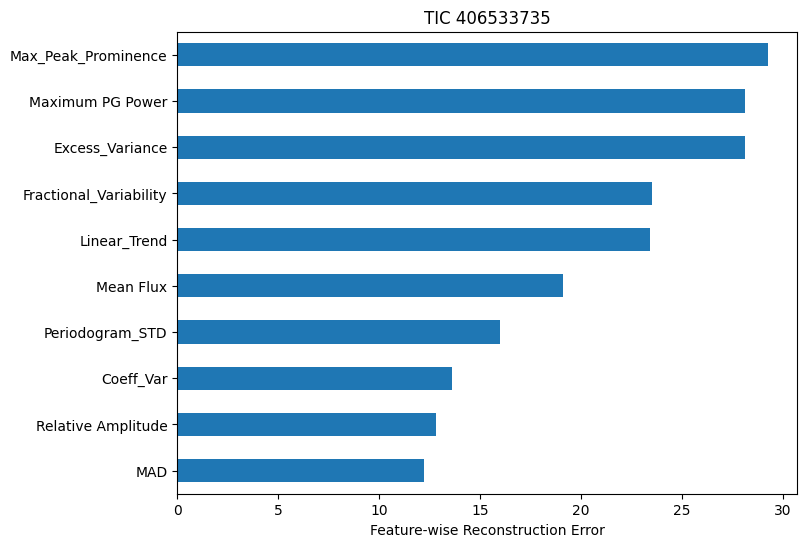

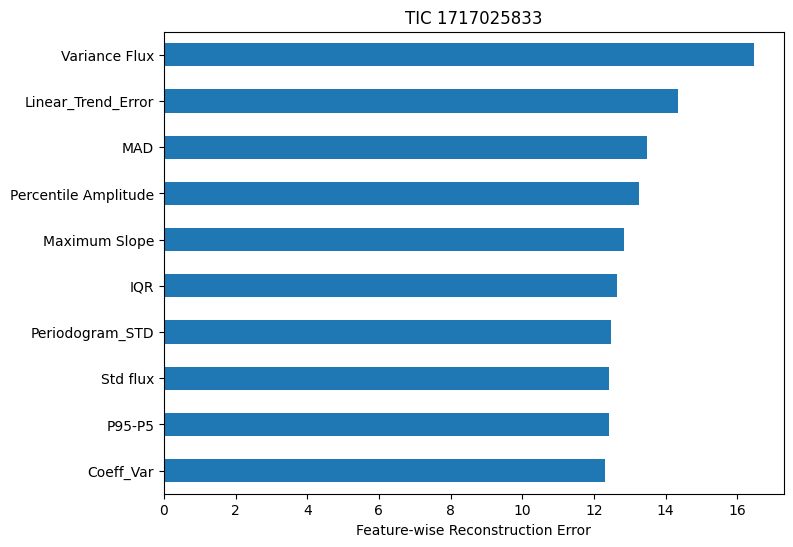

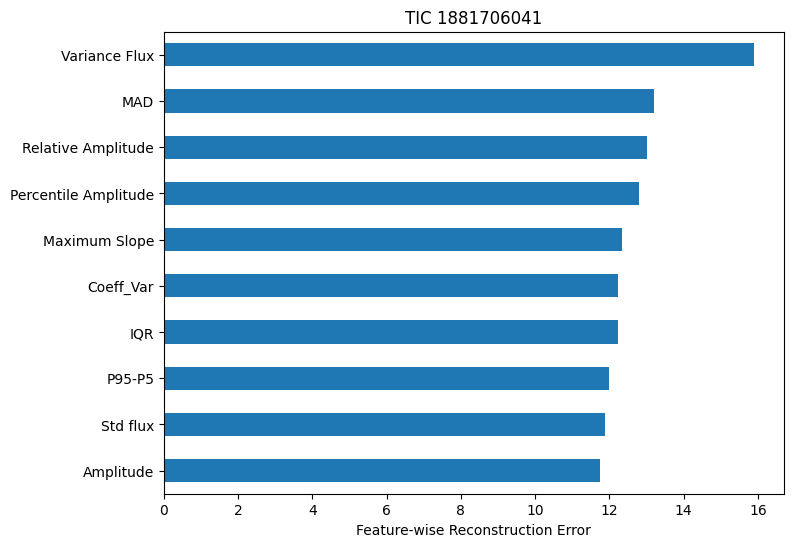

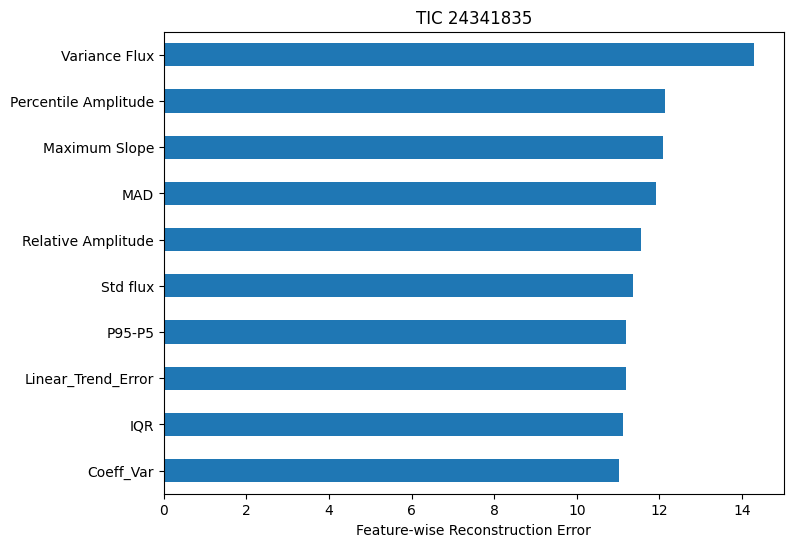

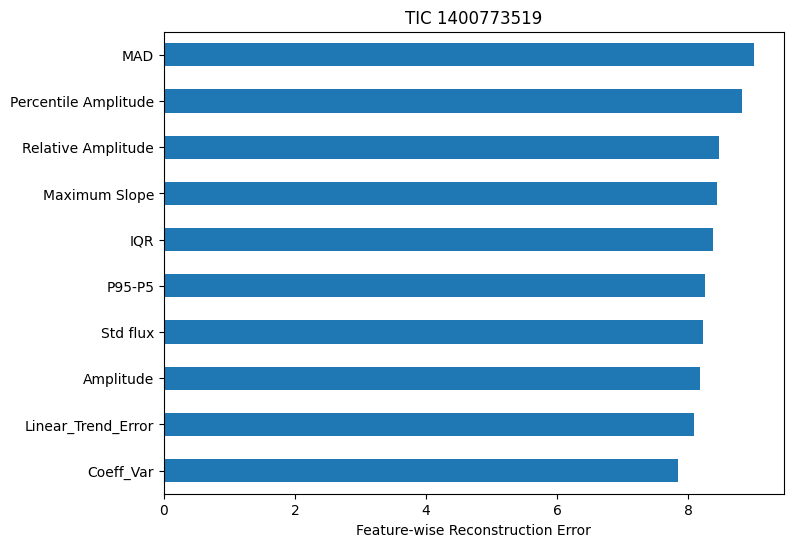

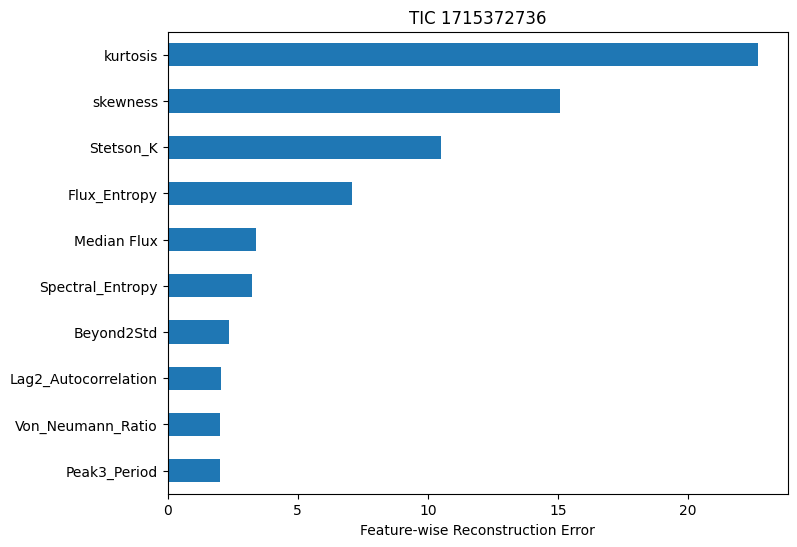

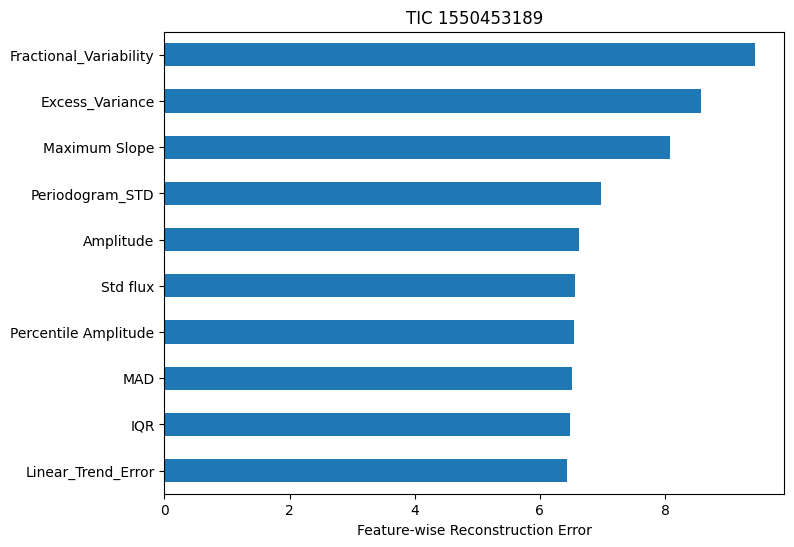

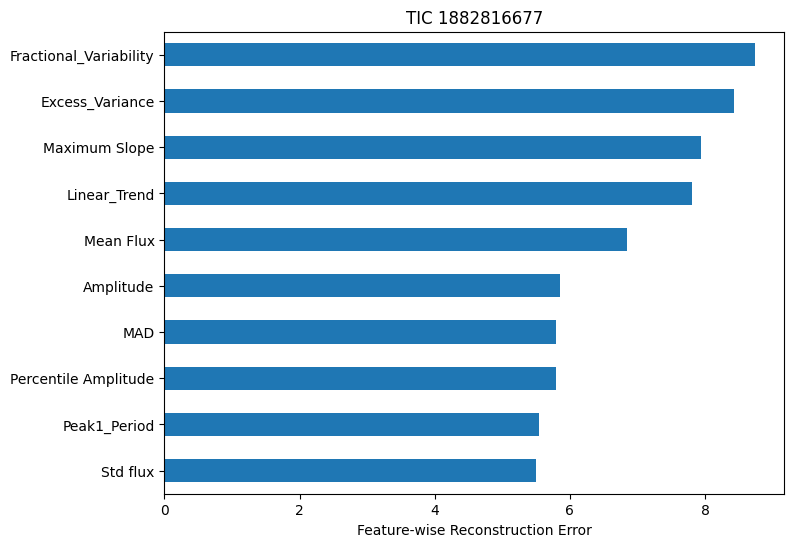

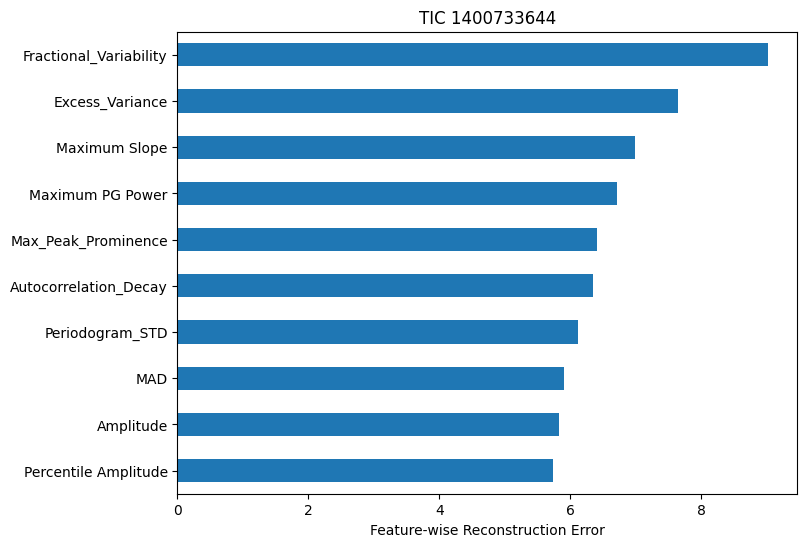

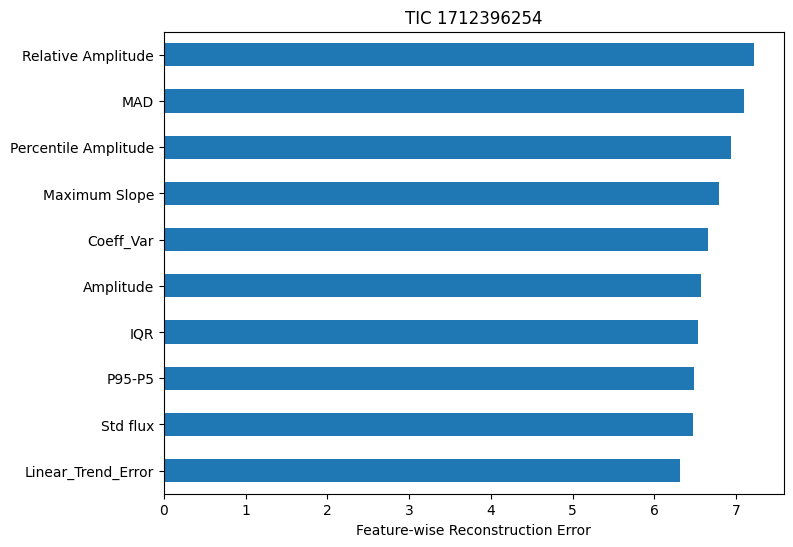

In [ ]:
# Plotting the features with the largest reconstruction errors for each top anomaly:

residual = abs(feature_matrix_scaled - feature_mat_predict)

for idx in top10_anomal.index:

    residual_series = pd.Series(
        residual[idx],
        index=feature_matrix.columns
    ).sort_values(ascending=False)

    plt.figure(figsize=(8,6))

    residual_series.head(10).plot(kind="barh")

    plt.gca().invert_yaxis()

    plt.title(f"TIC {df.loc[idx,'TIC ID']}")

    plt.xlabel("Feature-wise Reconstruction Error")

    plt.show()

#### Visual Inspection of the top anomaly candidates - Results of Dense Autoencoder

Just as the preprocessed light curves and their phase-folded forms were plotted for the anomaly candidates identified by the Isolation Forest, the same is done here for the top anomalies identified by the Dense Autoencoder.



/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=5.26e+01 electron / s +/- 5.10e+02 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 406533735


/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=1.02e+00 electron / s +/- 1.21e+01 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1717025833


/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=1.09e+00 electron / s +/- 1.26e+01 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1881706041


... (8 outputs left out)

/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=3.83e+01 electron / s +/- 2.00e+02 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1400733644


/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=2.32e+00 electron / s +/- 1.50e+01 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1712396254


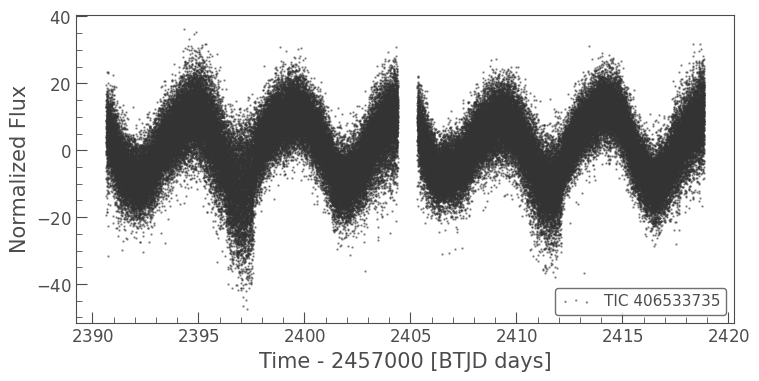

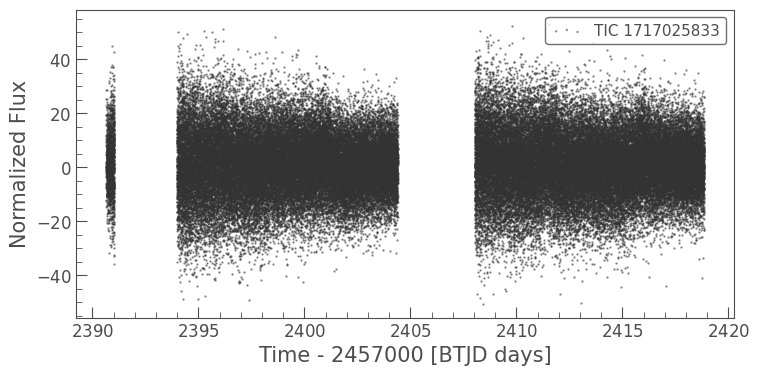

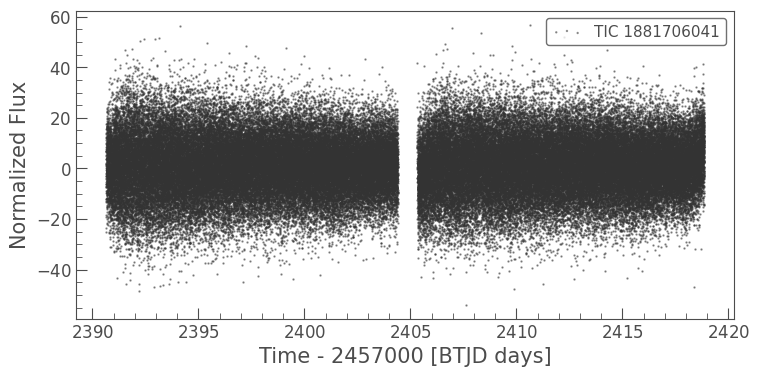

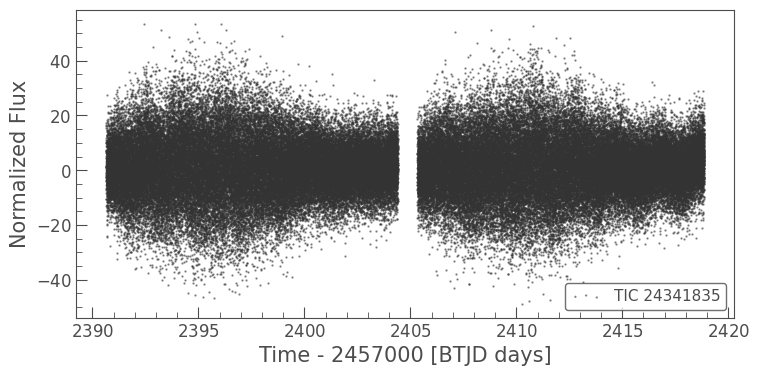

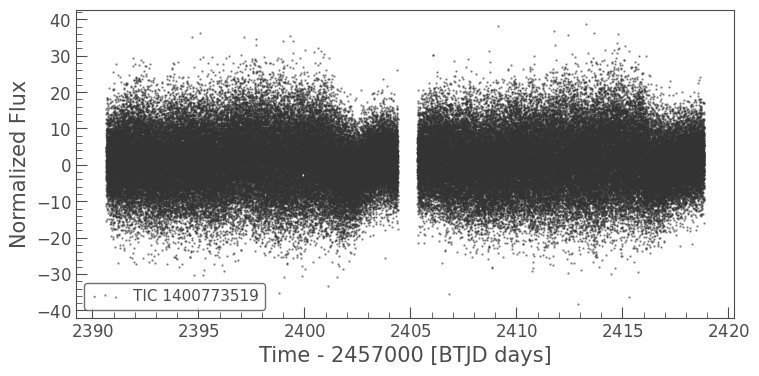

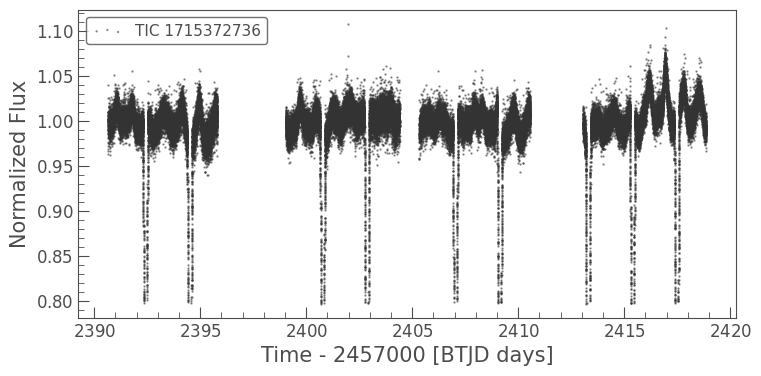

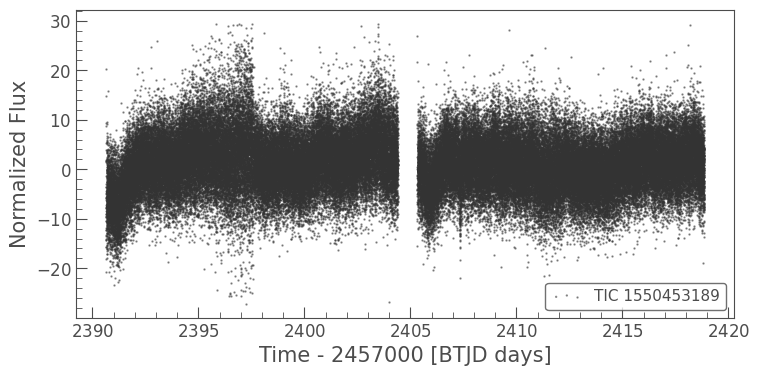

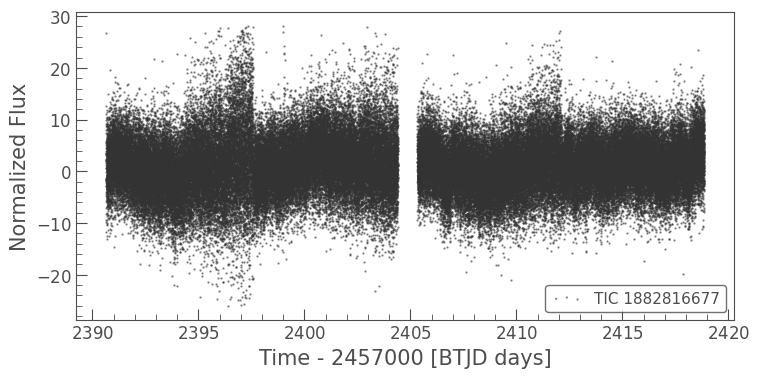

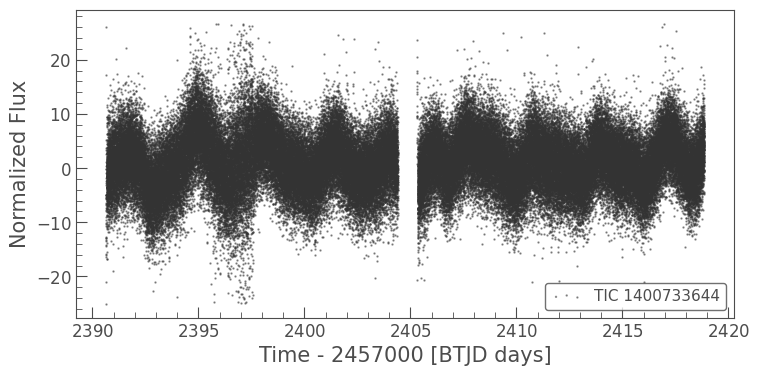

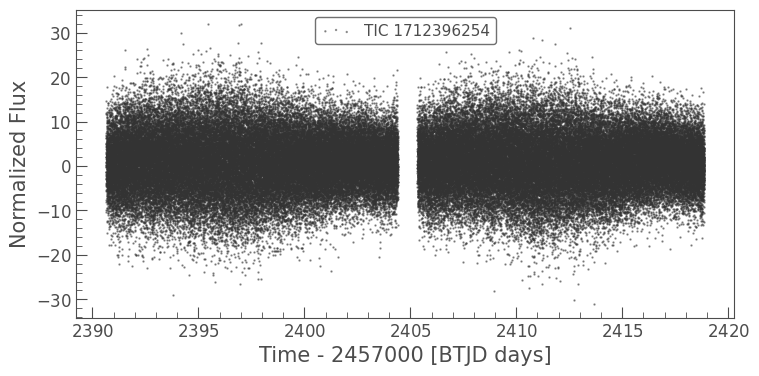

In [ ]:
for tic in top10_anomal["TIC ID"]:
    lc = extract_lightcurve(tic, 40)
    if lc is None:
        continue
    lc_clean = preprocess_lc(lc)
    print(f"TIC {tic}")
    lc_clean.scatter(alpha=0.5,s=2)

/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=5.26e+01 electron / s +/- 5.10e+02 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 406533735


/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=1.02e+00 electron / s +/- 1.21e+01 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1717025833


/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=1.09e+00 electron / s +/- 1.26e+01 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1881706041


... (8 outputs left out)

/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=3.83e+01 electron / s +/- 2.00e+02 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1400733644


/usr/local/lib/python3.12/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=2.32e+00 electron / s +/- 1.50e+01 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


TIC 1712396254


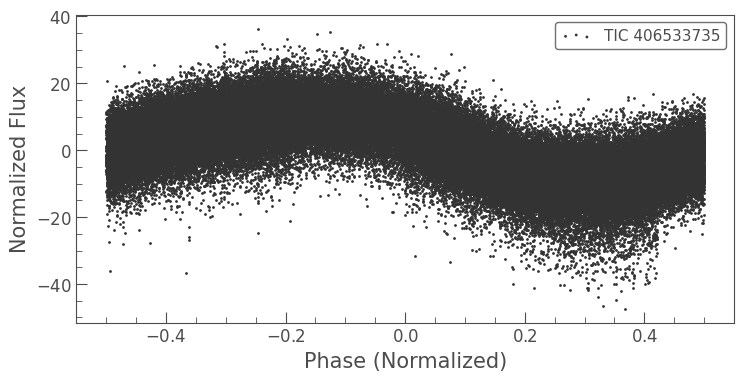

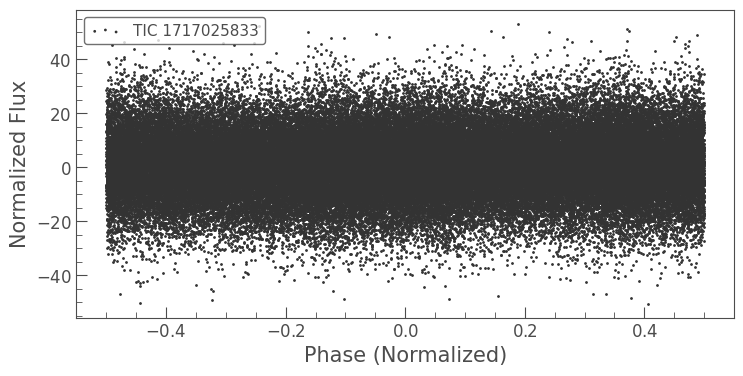

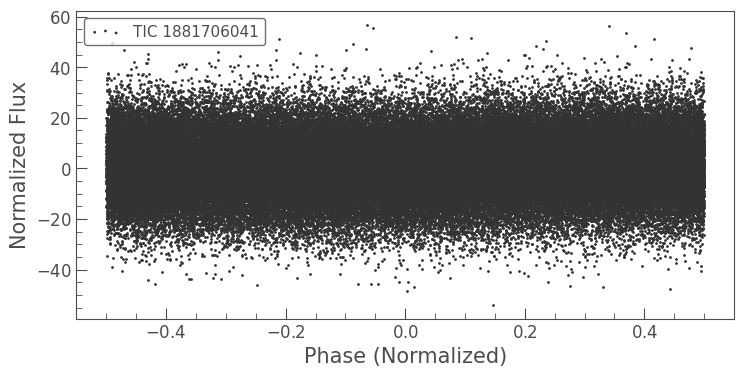

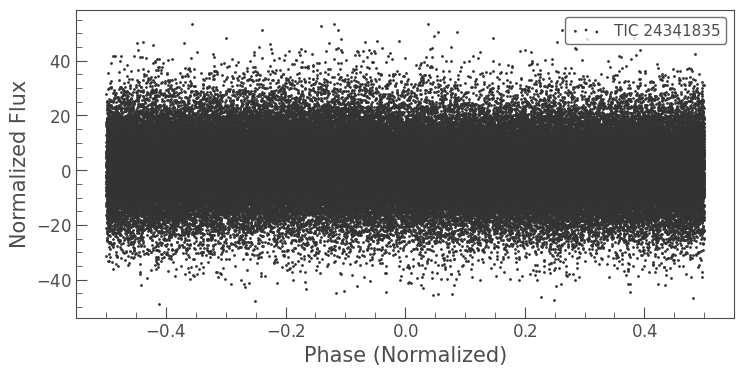

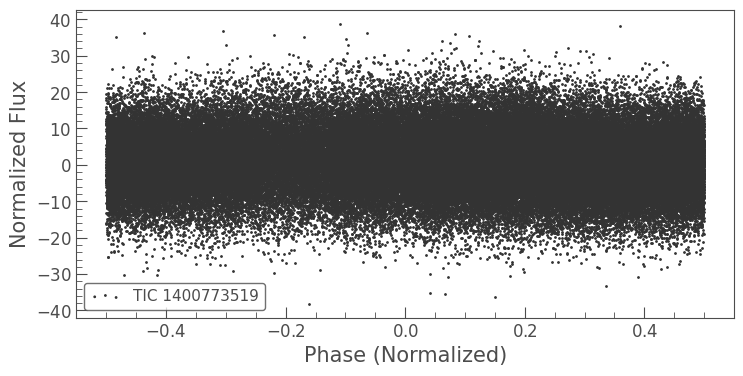

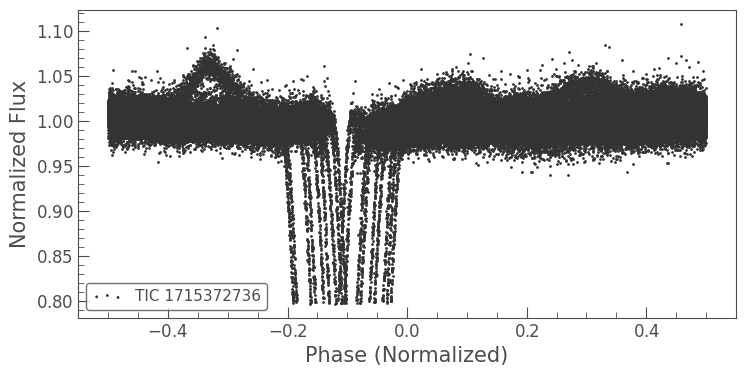

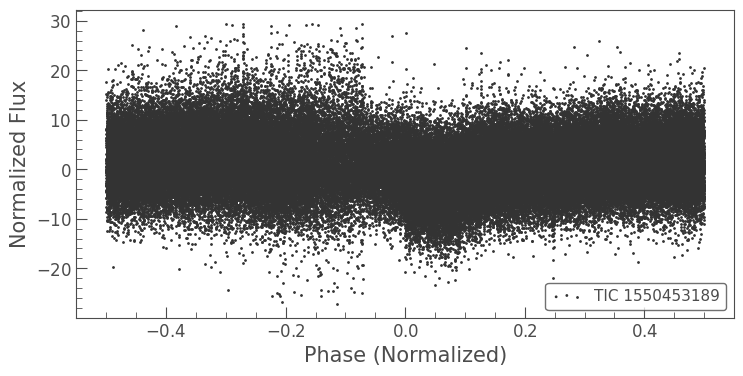

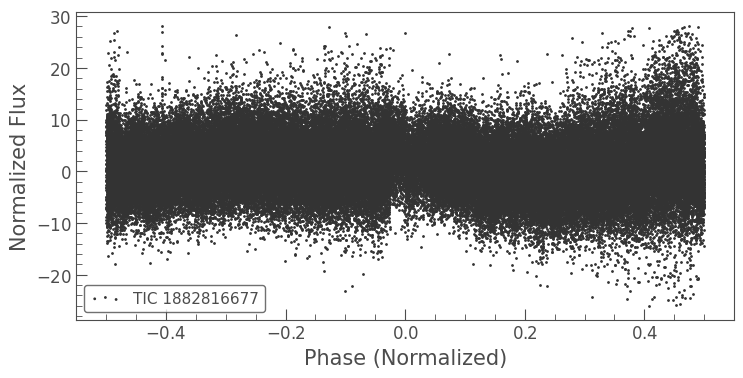

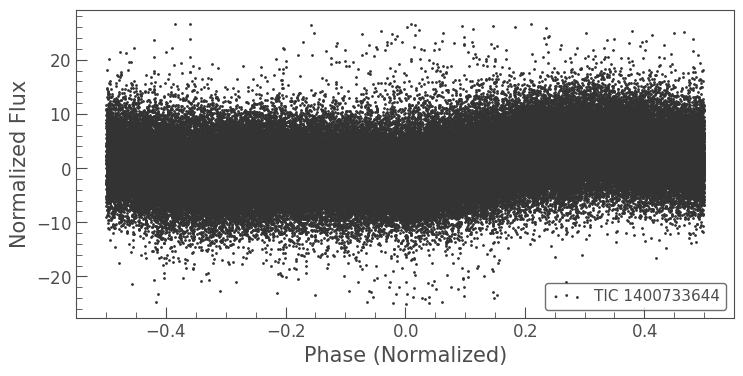

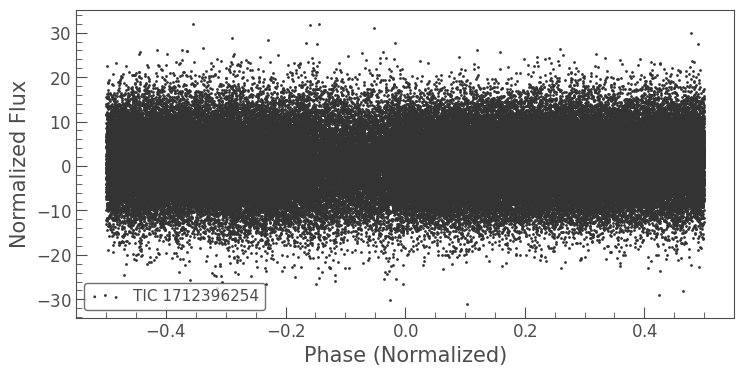

In [ ]:
for tic in top10_anomal["TIC ID"]:
    lc = extract_lightcurve(tic, 40)
    if lc is None:
        continue
    lc_clean = preprocess_lc(lc)
    print(f"TIC {tic}")
    # Read the period from your features table
    period_pg_ano = df.loc[df["TIC ID"] == tic, "Dominant Period"].values[0]
    folded = lc_clean.fold(period=period_pg_ano,normalize_phase=True)
    folded.scatter()

#### Final Table of Dense Autoencoder Results

We once again query the SIMBAD database to retrieve additional information about the top anomaly candidates identified by the Dense Autoencoder.

In [ ]:
customSimbad = Simbad()

customSimbad.add_votable_fields("otype", "otypes", "sp")

catalog_results_DAE = []

for tic in top10_anomal["TIC ID"]:
    print(f"Searching TIC {tic}")
    tic_result = Catalogs.query_criteria(catalog="TIC", ID=tic)

    if len(tic_result) == 0:
        continue

    ra = tic_result["ra"][0]
    dec = tic_result["dec"][0]

    coord = SkyCoord(ra=ra*u.deg, dec=dec*u.deg)

    simbad = customSimbad.query_region(coord, radius=2*u.arcsec)

    if simbad is None or len(simbad) == 0:

        catalog_results_DAE.append({ "TIC ID": tic, "RA": ra, "Dec": dec, "Found": False, "Main ID": None, "Object Type": None, "Spectral Type": None})
        continue

    catalog_results_DAE.append({"TIC ID": tic, "RA": ra, "Dec": dec, "Found": True, "Main ID": simbad["main_id"][0], "Object Type": simbad["otype"][0], "Spectral Type": simbad["sp_type"][0]})

catalog_df_DAE = pd.DataFrame(catalog_results_DAE)
display(catalog_df_DAE)

Searching TIC 406533735
Searching TIC 1717025833
Searching TIC 1881706041
Searching TIC 24341835


Searching TIC 1400773519
Searching TIC 1715372736
Searching TIC 1550453189
Searching TIC 1882816677
Searching TIC 1400733644
Searching TIC 1712396254


,TIC ID,RA,Dec,Found,Main ID,Object Type,Spectral Type
0,406533735,311.324372,81.084279,True,BD+80 670B,WD*,DA6.0
1,1717025833,289.771594,48.251676,True,PTF1 J191905.19+481506.2,CV*,
2,1881706041,295.827955,47.690941,True,PSO J295.8279+47.6909,HS?,
3,24341835,291.100991,31.935194,False,None,None,None
4,1400773519,262.698282,55.755129,True,CRTS J173047.5+554518,CV*,
5,1715372736,283.222104,36.234520,True,BD+36 3302,**,A2
6,1550453189,278.831492,39.304651,True,TIC 1550453189,HS?,
7,1882816677,294.811623,48.444801,True,GALEX J193914.7+482641,WD*,DA
8,1400733644,266.741333,55.150748,True,Gaia DR3 1418167865786389376,WD*,DA
9,1712396254,287.050134,29.215534,True,PSO J287.0501+29.2155,HS?,


## **Part 4 - Conclusion**



### Comparing the results of Isolation Forest and Dense Autoencoder

The table below compares the anomaly candidates identified by the Isolation Forest and Dense Autoencoder models. It also highlights which objects were detected by both unsupervised learning algorithms.

In [ ]:
# Create copies so the originals remain unchanged
if_table = catalog_df_IF.copy()
ae_table = catalog_df_DAE.copy()

# Add ranks (assuming the tables are already ordered from most anomalous to least)
if_table["IF Rank"] = range(1, len(if_table) + 1)
ae_table["AE Rank"] = range(1, len(ae_table) + 1)

# Merge the two tables on TIC ID
comparison = pd.merge(
    if_table[["TIC ID", "IF Rank", "Object Type"]],
    ae_table[["TIC ID", "AE Rank"]],
    on="TIC ID",
    how="outer"
)

# Rename for nicer display
comparison.rename(columns={"Object Type": "SIMBAD Type"}, inplace=True)

# Mark objects found by both methods
comparison["Detected by Both"] = comparison.apply(
    lambda row: "YES!" if pd.notna(row["IF Rank"]) and pd.notna(row["AE Rank"]) else "NO!",
    axis=1
)

# Replace missing ranks with a dash
comparison[["IF Rank", "AE Rank"]] = comparison[["IF Rank", "AE Rank"]].fillna("–")

# Reorder columns
comparison = comparison[
    ["TIC ID", "IF Rank", "AE Rank", "Detected by Both", "SIMBAD Type"]
]

display(comparison)

,TIC ID,IF Rank,AE Rank,Detected by Both,SIMBAD Type
0,24341835,4.0,4.0,YES!,None
1,406533735,1.0,1.0,YES!,WD*
2,1400733644,5.0,9.0,YES!,WD*
3,1400773519,9.0,5.0,YES!,CV*
4,1550453189,2.0,7.0,YES!,HS?
5,1712396254,10.0,10.0,YES!,HS?
6,1715372736,–,6.0,NO!,NaN
7,1717025833,6.0,2.0,YES!,CV*
8,1859153737,8.0,–,NO!,WD?
9,1881706041,3.0,3.0,YES!,HS?


It is to be noted that when the light curves of the two sets of results were plotted earlier, we witnessed Lightkurve normalization warnings due to their median PDCSAP flux being small when compared with their variability. Cross-matching with SIMBAD showed that many of these sources are known compact or eruptive systems. This suggests that the warnings are a reflection of the unusual photometric properties of these objects, rather than a failure in the preprocessing pipeline.


### Summary Statistics

The following simple calculations provide a quantitative comparison between the two sets of results obtained and allow us to know the percentage of agreement between them.



In [ ]:
#Top 10 Isolation Forest anomalies: 10
#Top 10 Dense Autoencoder anomalies: 10
#Common anomalies: 4
#Agreement = 40%...
agreement = []

for index in range(0,len(top_anomalies)):
    if top10_anomal["TIC ID"].isin([top_anomalies["TIC ID"].iloc[index]]).any() == True:
        agreement.append(1)
    else:
        agreement.append(0)

com = sum(agreement)
agree_percent = com / len(agreement) * 100

print(f"Number of top anomalies chosen from Isolation Forest: {len(top_anomalies)}")
print(f"Number of top anomalies chosen from Dense Autoencoder: {len(top10_anomal)}")
print(f"Number of anomalies detected by both Isolation Forest and Dense Autoencoder: {com}")
print(f"Percentage of agreement between Isolation Forest and Dense Autoencoder: {agree_percent}")

Number of top anomalies chosen from Isolation Forest: 10
Number of top anomalies chosen from Dense Autoencoder: 10
Number of anomalies detected by both Isolation Forest and Dense Autoencoder: 9
Percentage of agreement between Isolation Forest and Dense Autoencoder: 90.0


### Conclusion

Through this project, I have attempted to create and demonstrate an end-to-end pipeline for unsupervised anomaly detection on TESS Sector 40 light curves.

Both models successfully identified stars exhibiting unusual variability patterns. To gain additional context, visual inspection of the light curves, phase-folded analysis, and cross-matching with the SIMBAD database were performed. Through this, we were able to observe that several of the detected anomalies are classified as rare object types such as white dwarfs and cataclysmic variables. This provides confidence that the proposed pipeline is capable of identifying astrophysically interesting objects.

While the results of the two methods did not match exactly, a number of common anomaly candidates were detected. This demonstrates a certain level of agreement between the models, despite relying on fundamentally different anomaly detection principles, and suggests that these common anomalies are worth further investigation.

Overall, through this project, I learned and demonstrated the potential of unsupervised machine learning techniques for identifying unusual stellar behaviour within large astronomical datasets.


## **Part 5 - Future Work**

Anomaly detection by itself is not enough. For a huge dataset, we have the possibility of getting a large number of anomalies, for example, around 2000 anomalies. Thus, in the future, I would like to try to include another step after this anomaly detection pipeline.

This “step” is subjective, since not all anomalies are interesting. We will obtain anomalies due to both instrumental artefacts and astrophysical phenomena. An astronomer will of course be interested in the anomalies that correspond to real astrophysical phenomena. On the other hand, if one is interested in data quality, the anomalies corresponding to instrumental artefacts tend to be important as well.

Thus, it would be nice to integrate a system that recommends the type of anomalies one might be interested in. This can be attempted at being done using “Active Learning” in Machine Learning. While my current ability and knowledge about this is limited, this is surely something that would add value to this project and allow me to broaden my knowledge.

Apart from this, I would like to implement my project on larger datasets. This can be done by both stitching the light curves of the same objects from different sectors and considering multiple sectors. However, doing this wouldn’t be directly possible since there are several physical and instrumental variations that skew raw flux levels.


## **References**

1. Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., Devin, M., Ghemawat, S., Irving, G., Isard, M., Kudlur, M., Levenberg, J., Monga, R., Moore, S., Murray, D. G., Steiner, B., Tucker, P., Vasudevan, V., Warden, P., . . . Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. In 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI 16) (pp. 265–283). USENIX Association. https://www.usenix.org/conference/osdi16/technical-sessions/presentation/abadi

2. Collaboration, A., Price-Whelan, A. M., Lim, P. L., Earl, N., Starkman, N., Bradley, L., Shupe, D. L., Patil, A. A., Corrales, L., Brasseur, C. E., Nöthe, M., Donath, A., Tollerud, E., Morris, B. M., Ginsburg, A., Vaher, E., Weaver, B. A., Tocknell, J., Jamieson, W., . . . Zonca, A. (2022). The Astropy Project: Sustaining and growing a community-oriented open-source project and the latest major release (V5.0) of the Core package. Research Portal (Queen’s University Belfast). https://doi.org/10.3847/1538-4357/ac7c74

3. Ginsburg, A., Sipőcz, B. M., Brasseur, C. E., Cowperthwaite, P. S., Craig, M. W., Deil, C., Guillochon, J., Guzman, G., Liedtke, S., Lim, P. L., Lockhart, K. E., Mommert, M., Morris, B. M., Norman, H., Parikh, M., Persson, M. V., Robitaille, T. P., Segovia, J., Singer, L. P., . . . Woillez, J. (2019). astroquery: An Astronomical Web-querying Package in Python. The Astronomical Journal, 157(3), 98. https://doi.org/10.3847/1538-3881/aafc33

4. Jenkins, J. M., Twicken, J. D., McCauliff, S., Campbell, J., Sanderfer, D., Lung, D., Mansouri-Samani, M., Girouard, F., Tenenbaum, P., Klaus, T., Smith, J. C., Caldwell, D. A., Chacon, A. D., Henze, C., Heiges, C., Latham, D. W., Morgan, E., Swade, D., Rinehart, S., & Vanderspek, R. (2016c). The TESS science processing operations center. Proceedings of SPIE, the International Society for Optical Engineering/Proceedings of SPIE, 9913, 99133E. https://doi.org/10.1117/12.2233418

5. Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S. (2020). From local explanations to global understanding with explainable AI for trees. Nature Machine Intelligence, 2(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9

6. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation forest. In 2008 Eighth IEEE International Conference on Data Mining (pp. 413-422). IEEE. https://doi.org/10.1109/ICDM.2008.17

7. 2.0 - Data Product Overview - TESS Archive Documentation - MAST. (n.d.). https://outerspace.stsci.edu/spaces/TESS/pages/14563420/2.0+-+Data+Product+Overview

8. Crake, D. A., & Martínez-Galarza, J. R. (2023). Linking Anomalous Behaviour with Stellar Properties: An Unsupervised Exploration of TESS Light Curves. arXiv (Cornell University). https://doi.org/10.48550/arxiv.2301.10264

9. BRICS Astronomy/IDIA Data Analytics Coursebook and Lectures

10. Tssc. (n.d.). LightCurve objects. TESS. https://heasarc.gsfc.nasa.gov/docs/tess/LightCurve-object-Tutorial.html

11. List of features — feets 1.0.1 documentation. (n.d.). https://feets.readthedocs.io/en/latest/features.html

12. This project made use of Lightkurve, a Python package for Kepler and TESS data analysis (Lightkurve Collaboration, 2018).

13. https://medium.com/data-science/implementing-an-autoencoder-in-tensorflow-2-0-5e86126e9f7  

14. https://www.youtube.com/watch?v=ucgR0E_LXCk   




## **Feedback (Optional)**

If you wish to provide feedback to me regarding this project, please use the Google Form below. It would take less than a minute and would help me a lot!

[Link to the form](https://docs.google.com/forms/d/e/1FAIpQLSf1Pb4-wxfphfmkARyL9RQZC8EZp0pG3jZvmuoKAPBUbOdlDQ/viewform?usp=publish-editor)
